# Phase 2 — Data loading and exploratory analysis

In [53]:
import numpy as np

import preprocessing as pp
from helpers import load_csv_data

DATA_PATH = "dataset/"

x_train, x_test, y_train, train_ids, test_ids = load_csv_data(DATA_PATH)
col_names = pp.read_column_names(DATA_PATH + "x_train.csv")
col_idx = {name: j for j, name in enumerate(col_names)}   # name -> column index

In [54]:
print(f"x_train: {x_train.shape} | x_test: {x_test.shape} | y_train: {y_train.shape}")

values, counts = np.unique(y_train, return_counts=True)
print(f"Labels: {values} | Proportions: {counts / len(y_train)}")

# Trivial baselines
p = np.mean(y_train == 1)   # positive-class prevalence
print(f"p = {p:.4f} | acc always-negative = {1 - p:.4f} | F1 always-positive = {2*p/(1+p):.4f}")

x_train: (328135, 321) | x_test: (109379, 321) | y_train: (328135,)
Labels: [-1  1] | Proportions: [0.91169793 0.08830207]
p = 0.0883 | acc always-negative = 0.9117 | F1 always-positive = 0.1623


## Size and labels

- Training: 328 135 respondents x 321 features. Test: 109 379 respondents.
- Labels in $\{-1, +1\}$. Logistic regression needs $y \in \{0,1\}$: we use $y_{01} = (y+1)/2$ and the
  inverse map for the submission.
- **Strong imbalance:** positive prevalence $p = 0.0883$.

| Trivial classifier | Accuracy | F1 |
|---|---|---|
| Always negative | 0.912 | 0 |
| Always positive | 0.088 | $2p/(1+p) = 0.162$ |

**Consequence:** accuracy alone is misleading, because 91% is reached without learning anything. The main
metric is F1, and the decision threshold has to be tuned instead of being fixed at 0.5.

## Columns excluded a priori (codebook [1])

- **Target:** `_MICHD` is 1 if `CVDINFR4 = 1` (heart attack) or `CVDCRHD4 = 1` (angina or coronary heart
  disease) [1]. Neither variable is present in the dataset.
- **Administrative:** dates and identifiers, phone mode and residence, questionnaire version and language,
  survey weights and strata. They describe the interview process and the sampling design, not the health
  of the respondent.
- **Redundant:** many calculated variables are documented functions of other columns [1]. A variable is
  dropped when it is (almost) a linear combination of features already in the model: unit conversions
  (`WEIGHT2` -> `WTKG3`), converted frequencies (`FRUIT1` -> `FRUTDA1_`), groupings of one-hot encoded
  variables (`_RFHYPE5` from `BPHIGH4`), duplicates of the same question (`_DRDXAR1` = `HAVARTH3`),
  variables that can be rebuilt from the dummies of another one (`SMOKE100` = 2 if and only if
  `_SMOKER3` = 4). Thresholds on numeric variables are kept instead (e.g. `_RFHLTH` = `GENHLTH` >= 4),
  since they add a non-linearity to the linear model.
- `_STATE` (state of residence, 53 levels) is evaluated in cross-validation (4.4) and then excluded.

The complete list is in `preprocessing.py` and is summarized in 4.1.

In [55]:
# Fraction of NaN per column, per row, and the train/test gap (distribution shift check)
nan_train = np.isnan(x_train).mean(axis=0)
nan_test = np.isnan(x_test).mean(axis=0)

for tau in [0.0, 0.1, 0.3, 0.5, 0.8, 0.95]:
    print(f"Columns with > {tau:.0%} NaN: {np.sum(nan_train > tau)}")

nan_rows = np.isnan(x_train).mean(axis=1)
print(f"\nNaN per row -> min: {nan_rows.min():.3f} | median: {np.median(nan_rows):.3f} | "
      f"max: {nan_rows.max():.3f}")

diff = np.abs(nan_train - nan_test)
print(f"Max train/test NaN gap: {diff.max():.3f} in column {col_names[np.argmax(diff)]}")

Columns with > 0% NaN: 239
Columns with > 10% NaN: 182
Columns with > 30% NaN: 177
Columns with > 50% NaN: 147
Columns with > 80% NaN: 116
Columns with > 95% NaN: 68

NaN per row -> min: 0.249 | median: 0.433 | max: 0.679
Max train/test NaN gap: 0.004 in column HHADULT


## Missing values

| NaN fraction | > 0 | > 10% | > 30% | > 50% | > 80% | > 95% |
|---|---|---|---|---|---|---|
| Columns (out of 321) | 239 | 182 | 177 | 147 | 116 | 68 |

- **Per row:** every respondent has at least 25% missing values (median 43%). Dropping incomplete rows
  would empty the dataset: missingness must be handled **column-wise** (threshold $\tau$, imputation,
  missingness indicators, Phase 4).
- **Train vs test:** the largest gap in NaN fraction is 0.004 (`HHADULT`). The missingness mechanism is the
  same in the two sets, so a preprocessing learned on the training data applies to the test data.
- Most NaN are not random: they come from the *skip patterns* of the questionnaire, i.e. questions asked
  only to a subgroup (for example blood-pressure medication only to hypertensive respondents). Missingness
  is therefore informative, and we must check that it does not reveal the target (next cell).

In [56]:
# HAREHAB1 is asked only if CVDINFR4 = 1 (codebook): positive rate among respondents
answered = ~np.isnan(x_train[:, col_idx["HAREHAB1"]])
print(f"HAREHAB1 answered: {answered.sum()} | positive rate among answered: {np.mean(y_train[answered] == 1):.3f}")

HAREHAB1 answered: 773 | positive rate among answered: 1.000


## Leakage through skip patterns

For every question the codebook [1] gives the conditions under which it is not asked ("BLANK: Not asked or
Missing"). Searching those notes for the variables that define the target (`CVDINFR4`, `CVDCRHD4`) returns a
single question: `HAREHAB1` (rehabilitation after a heart attack), not asked if `CVDINFR4` is 2, 7, 9 or
missing. Hence $\text{HAREHAB1} \neq \text{NaN} \Rightarrow \texttt{CVDINFR4} = 1 \Rightarrow
\texttt{\_MICHD} = 1$.

**Check on the data:** 773 respondents, all positive (rate 1.000 against $p = 0.088$). The target is encoded
by the *missingness pattern*, not by the value, and it concerns about 2.7% of the positives.
**Decision: `HAREHAB1` excluded**, together with any missingness indicator of it.

The other skip patterns depend on legitimate characteristics: for example `STREHAB1` on stroke, the
cognitive module on age >= 45, the diabetes module on `DIABETE3`, the HPV vaccine questions on age <= 49.
In those cases the missingness pattern is informative, but it is not leakage.

In [57]:
# Per-column profile: missing fraction, distinct values, integer-valued, range
n_unique = np.array([len(np.unique(c[~np.isnan(c)])) for c in x_train.T])
is_int = np.array([np.all(c[~np.isnan(c)] % 1 == 0) for c in x_train.T])
col_min = np.nanmin(x_train, axis=0)
col_max = np.nanmax(x_train, axis=0)

print(f"{'column':<10} {'NaN':>5} {'uniq':>6} {'int':>5} {'min':>10} {'max':>10}")
for j in range(x_train.shape[1]):
    print(f"{col_names[j]:<10} {nan_train[j]:>5.2f} {n_unique[j]:>6} {str(is_int[j]):>5} "
          f"{col_min[j]:>10.2f} {col_max[j]:>10.2f}")

column       NaN   uniq   int        min        max
_STATE      0.00     53  True       1.00      72.00
FMONTH      0.00     12  True       1.00      12.00
IDATE       0.00    414  True 1012016.00 12312015.00
IMONTH      0.00     12  True       1.00      12.00
IDAY        0.00     31  True       1.00      31.00
IYEAR       0.00      2  True    2015.00    2016.00
DISPCODE    0.00      2  True    1100.00    1200.00
SEQNO       0.00  21780  True 2015000001.00 2015023235.00
_PSU        0.00  21780  True 2015000001.00 2015023235.00
CTELENUM    0.42      1  True       1.00       1.00
PVTRESD1    0.42      2  True       1.00       2.00
COLGHOUS    1.00      1  True       1.00       1.00
STATERES    0.42      1  True       1.00       1.00
CELLFON3    0.42      2  True       1.00       2.00
LADULT      1.00      2  True       1.00       2.00
NUMADULT    0.42     16  True       1.00      20.00
NUMMEN      0.43     12  True       0.00      18.00
NUMWOMEN    0.43     11  True       0.00      10.00

## 2.5 Column profile

For each feature: NaN fraction, number of distinct values, whether it is integer-valued, minimum and
maximum. Almost all columns are integer-valued with few distinct values: the dataset is largely categorical
or ordinal. The meaning of the codes is in the codebook [1]. The main conventions are:

| Family | Examples | Special codes |
|---|---|---|
| Yes/No, short scales | `CVDSTRK3`, `GENHLTH` | 7 = don't know, 9 = refused |
| Days, counts | `PHYSHLTH`, `AVEDRNK2` | 77 = don't know, 88 = none (-> 0), 99 = refused |
| Composite frequencies | `ALCDAY5`, `FRUIT1` | 1xx/2xx/3xx = per day/week/month; 555/888 = never; 777, 999 |
| Calculated categorical | `_RFHYPE5`, `_SMOKER3` | 9 = don't know/refused/missing |

The profile also lets us check the **transformations already applied in the course dataset** with respect to
the CDC file described by the codebook:
- implied decimals are already applied (`_BMI5` in [12, 98], `WTKG3` in kg, `HTM4` in m);
- "BLANK" values are NaN; some missing codes are already NaN (e.g. 99999 in `WTKG3`), others are only
  rescaled (99900 -> 999 in `MAXVO2_`, 99000 -> 99 in `STRFREQ_`).

In the `_RF...` variables the coding is 1 = no, 2 = yes, the opposite of the raw questions (1 = yes).

**Consequence:** the codes must be recoded (Phase 4), checking them both on the codebook and on the data.

In [58]:
def positive_rate_by_value(name, max_valid):
    """Print the positive rate and sample size for each valid value of a column."""
    col = x_train[:, col_idx[name]]
    parts = []
    for v in np.unique(col[col <= max_valid]):
        mask = col == v
        parts.append(f"{v:g}: {np.mean(y_train[mask] == 1):.3f} (n={mask.sum()})")
    print(f"{name} -> " + " | ".join(parts))

# Key clinical and demographic variables, with their largest valid code
for name, max_valid in [("_AGEG5YR", 13), ("SEX", 2), ("GENHLTH", 5), ("_RFHYPE5", 2),
                        ("_RFCHOL", 2), ("DIABETE3", 4), ("CVDSTRK3", 2), ("_SMOKER3", 4)]:
    positive_rate_by_value(name, max_valid)

_AGEG5YR -> 1: 0.005 (n=18145) | 2: 0.009 (n=14686) | 3: 0.011 (n=17122) | 4: 0.015 (n=18308) | 5: 0.023 (n=19296) | 6: 0.037 (n=22539) | 7: 0.056 (n=29693) | 8: 0.072 (n=34379) | 9: 0.100 (n=37210) | 10: 0.123 (n=36665) | 11: 0.161 (n=28190) | 12: 0.185 (n=20893) | 13: 0.222 (n=27066)
SEX -> 1: 0.112 (n=138783) | 2: 0.071 (n=189352)
GENHLTH -> 1: 0.021 (n=56937) | 2: 0.042 (n=108089) | 3: 0.091 (n=101880) | 4: 0.193 (n=43349) | 5: 0.319 (n=16992)
_RFHYPE5 -> 1: 0.038 (n=195416) | 2: 0.163 (n=131801)
_RFCHOL -> 1: 0.052 (n=163056) | 2: 0.161 (n=118755)
DIABETE3 -> 1: 0.221 (n=42223) | 2: 0.040 (n=2675) | 3: 0.067 (n=277049) | 4: 0.145 (n=5709)
CVDSTRK3 -> 1: 0.371 (n=13366) | 2: 0.076 (n=314032)
_SMOKER3 -> 1: 0.104 (n=32444) | 2: 0.098 (n=13230) | 3: 0.135 (n=90838) | 4: 0.062 (n=178357)


### Univariate association with the target

Positive rate per value (meaning of the codes from the codebook [1]; $p = 0.088$):

| Variable | Result |
|---|---|
| Age (`_AGEG5YR`, 1 = 18-24 ... 13 = 80+) | grows monotonically from 0.005 to 0.222 (about 44x): **strongest factor** |
| Sex (`SEX`, 1 = M, 2 = F) | 0.112 vs 0.071 |
| Self-reported health (`GENHLTH`, 1 = excellent ... 5 = poor) | monotone, from 0.021 to 0.319 |
| Hypertension (`_RFHYPE5`, 1 = no, 2 = yes) | 0.038 vs 0.163 |
| High cholesterol (`_RFCHOL`, 1 = no, 2 = yes) | 0.052 vs 0.161 |
| Stroke (`CVDSTRK3`, 1 = yes, 2 = no) | 0.371 vs 0.076 |

**Observations:**
- **Age.** The growth is strongly non-linear on the probability scale, but roughly linear on the logit scale
  ($\log\frac{r}{1-r}$ goes from -5.3 to -1.3 in nearly constant steps). The logistic model is therefore more
  appropriate than the MSE models, which work on the probability scale.
- **`DIABETE3` is not ordinal:** 1 = diabetes (0.221), 2 = only during pregnancy (0.040), 3 = no (0.067),
  4 = prediabetes (0.145). The risk ordering (2 < 3 < 4 < 1) does not follow the ordering of the codes, so it
  must be one-hot encoded.
- **`_SMOKER3` is not monotone:** 1 = daily smoker (0.104), 2 = occasional (0.098), 3 = former smoker
  (0.135), 4 = never (0.062). Former smokers have the highest rate. Plausible explanations: they are older
  on average (confounding by age), and the target is a *lifetime* diagnosis, so many may have quit **after**
  the diagnosis (reverse causation). This variable is one-hot encoded as well.
- These associations are **marginal**: they ignore the correlations between factors (e.g. age and
  hypertension). That is fine for a predictive task, but they must not be read as causal effects.

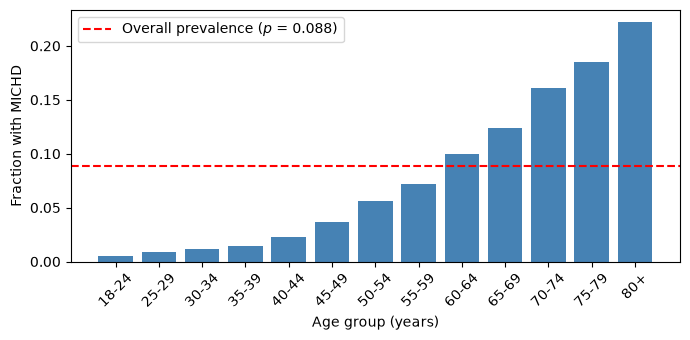

In [59]:
import matplotlib.pyplot as plt

# Positive rate by 5-year age group (_AGEG5YR: 1 = 18-24, ..., 13 = 80+)
age = x_train[:, col_idx["_AGEG5YR"]]
groups = np.arange(1, 14)
rates = [np.mean(y_train[age == g] == 1) for g in groups]
labels = ["18-24"] + [f"{25 + 5*i}-{29 + 5*i}" for i in range(11)] + ["80+"]

plt.figure(figsize=(7, 3.5))
plt.bar(labels, rates, color="steelblue")
plt.axhline(p, color="red", linestyle="--", label=f"Overall prevalence ($p$ = {p:.3f})")
plt.xlabel("Age group (years)")
plt.ylabel("Fraction with MICHD")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.savefig("figures/positive_rate_by_age.pdf")
plt.show()

**Figure 1** (`figures/positive_rate_by_age.pdf`): positive rate per 5-year age group; the dashed line is the
overall prevalence $p = 0.088$. The rate grows monotonically and exceeds $p$ from age 60 on.

## Phase 2 summary and decisions for the preprocessing

**Problem**
- Strongly imbalanced binary classification ($p = 0.088$). Main metric: F1; the decision threshold will be
  tuned.
- Labels $\{-1,+1\}$ -> $\{0,1\}$ for training, inverse map for the submission.

**Excluded columns** (list in 4.1)
- Administrative, leakage (`HAREHAB1`), redundant according to the codebook definitions, dates.

**Recoding**
- "Don't know" / "refused" (7, 77, 777, 9, 99, 999, ...) -> NaN; "none" / "never" (88, 555, 888) -> 0.
- Exceptions checked on the codebook for the columns that can enter the model.

**Feature handling**
- Columns with NaN fraction $> \tau$ dropped, with $\tau$ chosen by cross-validation.
- Median imputation plus missingness indicators, because the missingness pattern is informative.
- One-hot encoding for nominal variables and for ordinal variables with non-monotone risk.
- Standardization; winsorization of the continuous variables to be evaluated by cross-validation.

**General principle:** every preprocessing statistic is computed **on the training data of each fold only**,
to avoid data leakage.

# Phase 3 — Validation protocol

Goal: the tools needed to evaluate every preprocessing and modelling choice honestly. Internally the labels
are in $\{0,1\}$.

## 3.1 Metrics

All metrics derive from the confusion matrix (TP, FP, FN, TN). For F1 we use the form that is equivalent to
the harmonic mean of precision and recall,
$$F_1 = \frac{2PR}{P+R} = \frac{2\,TP}{2\,TP + FP + FN},$$
which stays defined even when the model predicts no positive ($TP + FP = 0$).

**Check:** the functions reproduce the analytic values of 2.3 (accuracy 0.9117 and F1 = 0 for "always
negative"; F1 = 0.1623 for "always positive").

In [60]:
from implementations import logistic_regression
from validation import (SEED, accuracy, f1_score, auc_score, stratified_kfold_indices,
                        cross_validate, print_cv, corrected_se)

K = 5


def sigmoid(t):
    """Logistic function."""
    return 1 / (1 + np.exp(-t))

In [61]:
# Map labels from {-1, 1} to {0, 1}
y01 = ((y_train + 1) / 2).astype(int)

always_neg = np.zeros_like(y01)
always_pos = np.ones_like(y01)

print(f"Always negative -> accuracy: {accuracy(y01, always_neg):.4f} | F1: {f1_score(y01, always_neg):.4f}")
print(f"Always positive -> accuracy: {accuracy(y01, always_pos):.4f} | F1: {f1_score(y01, always_pos):.4f}")

Always negative -> accuracy: 0.9117 | F1: 0.0000
Always positive -> accuracy: 0.0883 | F1: 0.1623


In [62]:
rng = np.random.default_rng(0)

print(f"Constant scores -> AUC: {auc_score(y01, np.zeros(len(y01))):.4f}   (expected 0.5)")
print(f"Perfect scores  -> AUC: {auc_score(y01, y01.astype(float)):.4f}   (expected 1.0)")
print(f"Random scores   -> AUC: {auc_score(y01, rng.random(len(y01))):.4f}   (expected ~0.5)")
print(f"Age alone       -> AUC: {auc_score(y01, x_train[:, col_idx['_AGE80']]):.4f}")

Constant scores -> AUC: 0.5000   (expected 0.5)
Perfect scores  -> AUC: 1.0000   (expected 1.0)
Random scores   -> AUC: 0.5020   (expected ~0.5)
Age alone       -> AUC: 0.7369


## 3.2 AUC

AUC measures the quality of the *ranking* of the scores, independently of the threshold:
$\text{AUC} = P(S^+ > S^-) + \tfrac12 P(S^+ = S^-)$. We compute it with the Mann-Whitney statistic (average
ranks for ties), in $O(n \log n)$.

**Check:**
- constant scores -> 0.5000 and perfect scores -> 1.0000, as expected;
- random scores -> 0.5020. Under the hypothesis of random scores the standard deviation of the AUC is
  $\sqrt{\frac{n^+ + n^- + 1}{12\, n^+ n^-}} \approx 0.0018$, so the observed deviation is about 1.1 standard
  deviations: compatible with chance.

**Result:** age alone (`_AGE80`) reaches **AUC = 0.737**. This is an important reference: a multivariate
model must clearly beat it to justify its complexity.

In [63]:
folds = stratified_kfold_indices(y01, K, SEED)

for i, f in enumerate(folds):
    print(f"Fold {i}: size {len(f)} | positive rate {y01[f].mean():.4f}")

all_idx = np.sort(np.concatenate(folds))
print(f"Folds form a partition of all samples: {np.array_equal(all_idx, np.arange(len(y01)))}")

Fold 0: size 65627 | positive rate 0.0883
Fold 1: size 65627 | positive rate 0.0883
Fold 2: size 65627 | positive rate 0.0883
Fold 3: size 65627 | positive rate 0.0883
Fold 4: size 65627 | positive rate 0.0883
Folds form a partition of all samples: True


## 3.3 Stratified split into $k = 5$ folds

Positives and negatives are shuffled and split separately, with a fixed seed (`SEED = 42`) for
reproducibility.

**Check:**
- all folds have 65 627 samples and prevalence 0.0883. The split is exact because
  $328\,135 = 5 \cdot 65\,627$, $28\,975 = 5 \cdot 5\,795$ positives and $299\,160 = 5 \cdot 59\,832$
  negatives;
- the sorted union of the folds equals $\{0, \dots, n-1\}$: every sample appears in exactly one fold.

In [64]:
def logreg_age_sex(x_tr, y_tr, x_va):
    """Logistic regression on standardized age and sex (statistics from the training fold only)."""
    cols = [col_idx["_AGE80"], col_idx["SEX"]]
    mean, std = x_tr[:, cols].mean(axis=0), x_tr[:, cols].std(axis=0)
    tx_tr = np.c_[np.ones(len(x_tr)), (x_tr[:, cols] - mean) / std]
    tx_va = np.c_[np.ones(len(x_va)), (x_va[:, cols] - mean) / std]
    w, _ = logistic_regression(y_tr, tx_tr, np.zeros(tx_tr.shape[1]), max_iters=500, gamma=0.5)
    return sigmoid(tx_va @ w)


f1s, accs, aucs, ths = cross_validate(x_train, y01, folds, logreg_age_sex, threshold=0.5)
print_cv("LogReg (age, sex)", f1s, accs, aucs, ths)

LogReg (age, sex)      F1: 0.0000 ± 0.0000 | acc: 0.9117 ± 0.0000 | AUC: 0.7529 ± 0.0033 | threshold: 0.500 ± 0.000


## 3.4 Cross-validation loop

`cross_validate` takes a function `train_and_predict(x_tr, y_tr, x_va)` that computes the preprocessing and
fits the model **on `x_tr` only**, and returns the probabilities on `x_va`. The absence of data leakage is
therefore guaranteed by the structure of the code.

**First model:** logistic regression on standardized age and sex (statistics of the training fold).

| Model | F1 (threshold 0.5) | Accuracy | AUC |
|---|---|---|---|
| LogReg (age, sex) | 0.000 | 0.912 | 0.753 ± 0.003 |

- **AUC 0.753 > 0.737 (age alone):** sex adds information and the ranking is good.
- **F1 = 0 at threshold 0.5:** no estimated probability exceeds 0.5 (the highest observed rate is 0.22), so
  the model always predicts "negative" and coincides with the trivial classifier. The threshold 0.5 is the
  Bayes-optimal rule for **accuracy**, not for F1.

**Consequence:** the threshold must be chosen to maximize F1.

In [65]:
f1s, accs, aucs, ths = cross_validate(x_train, y01, folds, logreg_age_sex)
print_cv("LogReg (age, sex)", f1s, accs, aucs, ths)

LogReg (age, sex)      F1: 0.2935 ± 0.0040 | acc: 0.7887 ± 0.0078 | AUC: 0.7529 ± 0.0033 | threshold: 0.148 ± 0.004


## 3.5 Threshold tuning

The threshold is a hyperparameter: for each outer fold it is chosen on an inner split of the training part
only (4/5 to fit, 1/5 to choose), then the model is refitted on the whole training part and evaluated on the
outer fold. Choosing it on the evaluation fold would introduce an optimistic bias.

| Model | Threshold | F1 | Accuracy | AUC |
|---|---|---|---|---|
| LogReg (age, sex) | 0.5 (fixed) | 0.000 | 0.912 | 0.753 |
| LogReg (age, sex) | 0.148 ± 0.004 (tuned) | **0.294 ± 0.004** | 0.789 | 0.753 |

- **F1 from 0 to 0.294** with the same model: only the decision rule changes. The AUC is unchanged because
  the threshold does not modify the ranking.
- **Accuracy drops (0.912 -> 0.789):** lowering the threshold turns many negatives into false positives. It
  is the expected trade-off when optimizing F1 instead of accuracy.
- **Threshold $\approx F_1^*/2$:** for a calibrated classifier the F1-maximizing threshold is half of the
  optimal F1 [2]. Here $0.2935 / 2 \approx 0.147$ against the selected 0.148: the result confirms the theory
  and indicates that the logistic model produces well-calibrated probabilities.
- The threshold is stable across folds (± 0.004), so choosing it on an inner split is reliable.

# Phase 4 — Preprocessing

The pipeline is implemented in **`preprocessing.py`**, which is also used by `run.py`: the notebook imports
it (as `pp`) instead of redefining it, so that there is a single source of truth. This phase documents and
justifies every choice recorded in that module, and reproduces the diagnostics that led to it.

In [66]:
# Columns excluded a priori (lists and justification in preprocessing.py)
for name, group in [("administrative", pp.ADMIN), ("leakage", pp.LEAKAGE), ("redundant", pp.REDUNDANT),
                    ("dates", pp.DATES), ("not used", pp.NOT_USED)]:
    print(f"{name:<15} {len(group):>3}")

# Sanity check: a typo in a name would silently leave that column in the data
print(f"\nNames not found: {[n for n in pp.EXCLUDED if n not in col_idx]}")

kept = np.array([j for j, name in enumerate(col_names) if name not in pp.EXCLUDED])
print(f"Excluded: {len(pp.EXCLUDED)} | kept: {len(kept)}")

for tau in [0.1, 0.3, 0.5, 0.8, 0.95, 1.0]:
    print(f"Kept columns with NaN fraction <= {tau:.0%}: {np.sum(nan_train[kept] <= tau)}")

administrative   31
leakage           1
redundant        68
dates             2
not used          1

Names not found: []
Excluded: 103 | kept: 218
Kept columns with NaN fraction <= 10%: 69
Kept columns with NaN fraction <= 30%: 73
Kept columns with NaN fraction <= 50%: 90
Kept columns with NaN fraction <= 80%: 107
Kept columns with NaN fraction <= 95%: 154
Kept columns with NaN fraction <= 100%: 218


## 4.1 A priori exclusion

Excluded columns (103): administrative (31), leakage (`HAREHAB1`), redundant (68), dates (2) and `_STATE`
(nominal with 53 levels: meaningless as a number, and its one-hot encoding gives no measurable gain, see
4.4). The redundancies come from the codebook definitions [1]: a variable is dropped when it is (almost) a
linear combination of features already in the model, after our encoding.

Remaining columns: **218**. How many survive the threshold on the NaN fraction (before recoding, see 4.2b):

| $\tau$ | 10% | 30% | 50% | 80% | 95% | 100% |
|---|---|---|---|---|---|---|
| Columns | 69 | 73 | 90 | 107 | 154 | 218 |

$\tau$ will be chosen by cross-validation on the grid $\{0.1, 0.3, 0.5, 0.8, 0.9\}$. We stay below 93%
because a few composite frequencies without a calculated version (`BLDSUGAR`, `FEETCHK2`, `LONGWTCH`, 93-94%
NaN) are not converted.

In [67]:
# Recoding rules for each kept column: name -> (codes to NaN, codes to 0)
kept_names, recode = pp.recoding_rules(x_train, col_names)

for name in ["GENHLTH", "PHYSHLTH", "EMPLOY1", "AVEDRNK2", "_AGE80", "DIABAGE2"]:
    print(f"{name:<9} -> NaN: {recode[name][0]} | -> 0: {recode[name][1]}")

GENHLTH   -> NaN: [9, 7] | -> 0: []
PHYSHLTH  -> NaN: [99, 77] | -> 0: [88]
EMPLOY1   -> NaN: [9] | -> 0: []
AVEDRNK2  -> NaN: [99, 77] | -> 0: [88]
_AGE80    -> NaN: [] | -> 0: []
DIABAGE2  -> NaN: [98, 99] | -> 0: []


## 4.2 Recoding of the special codes

### 4.2a Rules

Codebook conventions [1], by family (determined by the maximum value of the column):

| Maximum | -> NaN ("don't know", "refused") | -> 0 ("none", "never") |
|---|---|---|
| <= 9 | 9, 7 | — |
| <= 99 | 99, 77 | 88 |
| <= 999 | 999, 777 | 555, 888 |

- **7/77/777 as a valid answer:** treated as "don't know" only if the immediately preceding value (6/76/776)
  is absent (*hole rule*). Example: in `EMPLOY1`, 7 means "retired", so no code is mapped to NaN except 9.
- **Exceptions checked on the codebook**, limited to the columns that can enter the model (NaN <= 90%, the
  largest value of the $\tau$ grid):
  - 7 or 77 = "don't know" even without a hole: `RCSRLTN2` (1-6 valid), `AVEDRNK2`, `DRNK3GE5`, `MAXDRNKS`,
    `HHADULT` (1-76 valid);
  - complete rules: `DROCDY3_` (900), `_DRNKWEK` (99900), `DIABAGE2` (98, 99; 88 is a valid age),
    `STRFREQ_`, `PAFREQ1_`, `PAFREQ2_` (99 = 99000 "don't know", with three implied decimals).
- **No rule** for the calculated continuous variables (values such as 77 or 888 are real measurements).

The rules depend only on the meaning of the codes, not on statistics of the data: they apply identically to
train and test, without leakage.

In [68]:
xr_train = pp.apply_recoding(x_train, col_names, kept_names, recode)
xr_test = pp.apply_recoding(x_test, col_names, kept_names, recode)
kept_idx = {name: k for k, name in enumerate(kept_names)}   # name -> column index in xr_*

before = x_train[:, kept]
print(f"Values mapped to NaN: {np.sum(~np.isnan(before) & np.isnan(xr_train))}")
print(f"Values mapped to 0:   {np.sum((before != 0) & (xr_train == 0))}")

# Missingness before and after recoding
nan_kept = np.isnan(before).mean(axis=0)
nan_recoded = np.isnan(xr_train).mean(axis=0)
print()
for tau in [0.1, 0.3, 0.5, 0.8, 0.9]:
    print(f"NaN fraction <= {tau:.0%}: {np.sum(nan_kept <= tau)} columns before, "
          f"{np.sum(nan_recoded <= tau)} after")

# Columns whose missingness increased the most
print()
for k in np.argsort(nan_recoded - nan_kept)[::-1][:5]:
    print(f"{kept_names[k]:<10} NaN: {nan_kept[k]:.3f} -> {nan_recoded[k]:.3f}")

# No special codes left in representative columns
print()
for name in ["GENHLTH", "PHYSHLTH", "EMPLOY1", "INCOME2"]:
    col = xr_train[:, kept_idx[name]]
    print(f"{name:<9} values: {np.unique(col[~np.isnan(col)])}")

Values mapped to NaN: 873198
Values mapped to 0:   739001

NaN fraction <= 10%: 69 columns before, 61 after
NaN fraction <= 30%: 73 columns before, 71 after
NaN fraction <= 50%: 90 columns before, 89 after
NaN fraction <= 80%: 107 columns before, 106 after
NaN fraction <= 90%: 123 columns before, 123 after

_CHISPNC   NaN: 0.276 -> 0.859
_HCVU651   NaN: 0.000 -> 0.359
INCOME2    NaN: 0.008 -> 0.179
_PAREC1    NaN: 0.000 -> 0.130
_PACAT1    NaN: 0.000 -> 0.126

GENHLTH   values: [1. 2. 3. 4. 5.]
PHYSHLTH  values: [ 0.  1.  2.  3.  4.  5.  6.  7.  8.  9. 10. 11. 12. 13. 14. 15. 16. 17.
 18. 19. 20. 21. 22. 23. 24. 25. 26. 27. 28. 29. 30.]
EMPLOY1   values: [1. 2. 3. 4. 5. 6. 7. 8.]
INCOME2   values: [1. 2. 3. 4. 5. 6. 7. 8.]


### 4.2b Application and check

Converted values: **873 198 -> NaN** ("don't know", "refused") and **739 001 -> 0** ("none", "never").
No code is left in the control columns: `GENHLTH` in {1,...,5}, `PHYSHLTH` in {0,...,30},
`EMPLOY1` in {1,...,8}, `INCOME2` in {1,...,8}.

| $\tau$ | 10% | 30% | 50% | 80% | 90% |
|---|---|---|---|---|---|
| Columns before recoding | 69 | 73 | 90 | 107 | 123 |
| Columns after recoding | 61 | 71 | 89 | 106 | 123 |

True missingness is larger than the one visible in the original NaN: the threshold $\tau$ must be applied
**after** recoding.

Columns with the largest increase in missingness (meaning from the codebook [1]):
- `_CHISPNC` (27.6% -> 85.9%): ethnicity of the selected child, undefined for respondents without children.
- `_HCVU651` (0% -> 35.9%): defined only for ages 18-64, and code 9 covers everyone above 64.
- `INCOME2` (0.8% -> 17.9%): almost one respondent in five does not report their income.
- `_PAREC1`, `_PACAT1` (0% -> 13%): not computable when the physical-activity answers are missing.

In all these cases the NaN carries information, which motivates the missingness indicators.

In [69]:
# Check on a single split (fold 0 as validation, tau = 0.5)
va = folds[0]
tr = np.concatenate(folds[1:])

prep = pp.fit_preprocessing(xr_train[tr], tau=0.5)
tx_tr, tx_va = pp.transform(xr_train[tr], prep), pp.transform(xr_train[va], prep)

print(f"Columns kept: {len(prep['num_cols']) + len(prep['cat_cols'])} | "
      f"missingness indicators: {len(prep['ind_cols'])} | constant removed: {np.sum(~prep['keep'])} | "
      f"features incl. bias: {tx_tr.shape[1]}")
print(f"NaN left -> train: {np.isnan(tx_tr).any()} | validation: {np.isnan(tx_va).any()}")
for name, tx in [("Train", tx_tr), ("Validation", tx_va)]:
    m, s = tx[:, 1:].mean(axis=0), tx[:, 1:].std(axis=0)
    print(f"{name:<10} max |mean|: {np.abs(m).max():.2e} | std in [{s.min():.3f}, {s.max():.3f}]")

Columns kept: 89 | missingness indicators: 81 | constant removed: 0 | features incl. bias: 171
NaN left -> train: False | validation: False
Train      max |mean|: 7.19e-16 | std in [1.000, 1.000]
Validation max |mean|: 9.85e-03 | std in [0.781, 1.226]


## 4.3 Preprocessing pipeline

The preprocessing is split into `fit_preprocessing` (statistics learned **on the training fold only**) and
`transform` (applied identically to validation and test data):
1. columns with NaN fraction $\le \tau$;
2. winsorization of the continuous variables at the 1st and 99th percentiles (evaluated in 4.5);
3. median imputation of the numeric columns;
4. one-hot encoding of the nominal variables (evaluated in 4.4);
5. one missingness indicator per **distinct pattern** (identical indicators would be redundant and would
   worsen the conditioning);
6. removal of constant features;
7. standardization with the $\mu, \sigma$ of the training fold, plus the bias column.

**Check (fold 0, $\tau = 0.5$):** 89 columns, 81 missingness indicators, 171 features including the bias.
No NaN left.
- Training: means $\approx 10^{-15}$ (rounding error), standard deviations exactly 1.
- Validation: $\max|\text{mean}| = 0.010$, compatible with sampling variability (standard error per feature
  $\approx 1/\sqrt{65\,627} \approx 0.004$; the maximum over all features is expected around 3 standard
  errors). The standard deviations far from 1 come from rare indicators.

In [70]:
import time

y_tr, y_va = y01[tr], y01[va]

# Step size from the Lipschitz constant of the gradient of the mean logistic loss
L = np.linalg.eigvalsh(tx_tr.T @ tx_tr / len(tx_tr)).max() / 4
gamma = 1 / L
print(f"L = {L:.3f} -> gamma = 1/L = {gamma:.4f}")

# Gradient descent in blocks, monitoring convergence
w = np.zeros(tx_tr.shape[1])
done = 0
start = time.time()
for total in [250, 500, 1000, 2000]:
    w, loss = logistic_regression(y_tr, tx_tr, w, total - done, gamma)
    done = total
    grad = tx_tr.T @ (sigmoid(tx_tr @ w) - y_tr) / len(y_tr)
    print(f"iters {total:>5} | train loss {loss:.5f} | grad norm {np.linalg.norm(grad):.2e} | "
          f"val AUC {auc_score(y_va, sigmoid(tx_va @ w)):.4f} | {time.time() - start:.0f} s")

L = 5.708 -> gamma = 1/L = 0.1752
iters   250 | train loss 0.22647 | grad norm 1.30e-02 | val AUC 0.8573 | 4 s
iters   500 | train loss 0.22351 | grad norm 4.93e-03 | val AUC 0.8586 | 8 s
iters  1000 | train loss 0.22265 | grad norm 1.94e-03 | val AUC 0.8594 | 16 s
iters  2000 | train loss 0.22239 | grad norm 6.85e-04 | val AUC 0.8597 | 31 s


### Step size and convergence

The mean logistic loss has an $L$-Lipschitz gradient with $L = \lambda_{\max}(X^\top X/n)/4$, because
$\nabla^2 f = \frac1n X^\top S X$ with $S = \mathrm{diag}(\sigma_i(1-\sigma_i)) \preceq \frac14 I$. With step
$\gamma = 1/L$ the descent lemma guarantees that the loss decreases at every iteration.

Fold 0, $\tau = 0.5$: $L = 5.71$, hence $\gamma = 0.175$. The value 0.5 used with two features would exceed
$2/L = 0.350$, beyond which convergence is no longer guaranteed.

| Iterations | Training loss | $\lVert\nabla f\rVert$ | Validation AUC | Time |
|---|---|---|---|---|
| 250 | 0.2265 | 1.3e-2 | 0.8573 | 4 s |
| 500 | 0.2235 | 4.9e-3 | 0.8586 | 8 s |
| 1000 | 0.2227 | 1.9e-3 | 0.8594 | 16 s |
| 2000 | 0.2224 | 6.9e-4 | 0.8597 | 32 s |

- The gradient norm shrinks by about 2.6x at every doubling of the iterations, i.e.
  $\lVert\nabla f\rVert \propto k^{-1.4}$: sublinear convergence, typical of gradient descent on an
  ill-conditioned problem.
- Beyond 1000 iterations the AUC gains 0.0003 at twice the cost. **Choice: 1000 iterations** (also checked on
  the final configuration, cell at the end of Phase 4).
- **AUC 0.86 against 0.753 for the baseline (age, sex):** the full preprocessing substantially improves the
  ranking.

In [71]:
def make_logreg(tau, nominal=frozenset(), continuous=frozenset(), max_iters=1000):
    """Return a train_and_predict function: preprocessing (threshold tau, one-hot encoding of
    `nominal`, winsorization of `continuous`), then logistic regression by gradient descent
    with step size 1/L."""
    def train_and_predict(x_tr, y_tr, x_va):
        prep = pp.fit_preprocessing(x_tr, tau, nominal, continuous)
        tx_tr, tx_va = pp.transform(x_tr, prep), pp.transform(x_va, prep)
        L = np.linalg.eigvalsh(tx_tr.T @ tx_tr / len(tx_tr)).max() / 4
        w, _ = logistic_regression(y_tr, tx_tr, np.zeros(tx_tr.shape[1]), max_iters, 1 / L)
        return sigmoid(tx_va @ w)
    return train_and_predict


results = {}
for tau in [0.1, 0.3, 0.5, 0.8, 0.9]:
    start = time.time()
    results[f"tau={tau}"] = cross_validate(xr_train, y01, folds, make_logreg(tau))
    print_cv(f"tau={tau}", *results[f"tau={tau}"])
    print(f"{'':<22} ({time.time() - start:.0f} s)")

tau=0.1                F1: 0.4133 ± 0.0027 | acc: 0.8628 ± 0.0054 | AUC: 0.8517 ± 0.0004 | threshold: 0.185 ± 0.008
                       (126 s)
tau=0.3                F1: 0.4215 ± 0.0037 | acc: 0.8633 ± 0.0067 | AUC: 0.8578 ± 0.0010 | threshold: 0.185 ± 0.011
                       (139 s)
tau=0.5                F1: 0.4214 ± 0.0027 | acc: 0.8696 ± 0.0073 | AUC: 0.8578 ± 0.0009 | threshold: 0.197 ± 0.013
                       (172 s)
tau=0.8                F1: 0.4250 ± 0.0038 | acc: 0.8714 ± 0.0016 | AUC: 0.8586 ± 0.0008 | threshold: 0.199 ± 0.004
                       (452 s)
tau=0.9                F1: 0.4258 ± 0.0034 | acc: 0.8748 ± 0.0018 | AUC: 0.8589 ± 0.0010 | threshold: 0.206 ± 0.006
                       (207 s)


In [72]:
# Paired comparison with the best tau, with the Nadeau-Bengio corrected standard error [3]
best = results["tau=0.9"]
for tau in [0.3, 0.5, 0.8]:
    d_f1 = best[0] - results[f"tau={tau}"][0]
    d_auc = best[2] - results[f"tau={tau}"][2]
    se_f1, se_auc = corrected_se(d_f1, K), corrected_se(d_auc, K)
    print(f"0.9 vs {tau} -> dF1: {d_f1.mean():+.4f} (SE {se_f1:.4f}, {d_f1.mean() / se_f1:.1f} SE) | "
          f"dAUC: {d_auc.mean():+.4f} (SE {se_auc:.4f}, {d_auc.mean() / se_auc:.1f} SE)")

0.9 vs 0.3 -> dF1: +0.0042 (SE 0.0023, 1.8 SE) | dAUC: +0.0011 (SE 0.0003, 4.0 SE)
0.9 vs 0.5 -> dF1: +0.0044 (SE 0.0026, 1.7 SE) | dAUC: +0.0011 (SE 0.0002, 4.4 SE)
0.9 vs 0.8 -> dF1: +0.0008 (SE 0.0013, 0.6 SE) | dAUC: +0.0003 (SE 0.0002, 1.6 SE)


### Choice of the threshold $\tau$ (5-fold CV, logistic regression, 1000 iterations, tuned decision threshold)

| $\tau$ | F1 | Accuracy | AUC | Threshold |
|---|---|---|---|---|
| 0.1 | 0.4133 ± 0.0027 | 0.863 | 0.8517 ± 0.0004 | 0.185 |
| 0.3 | 0.4215 ± 0.0037 | 0.863 | 0.8578 ± 0.0010 | 0.185 |
| 0.5 | 0.4214 ± 0.0027 | 0.870 | 0.8578 ± 0.0009 | 0.197 |
| **0.8** | **0.4250 ± 0.0038** | 0.871 | **0.8586 ± 0.0008** | 0.199 |
| 0.9 | 0.4258 ± 0.0034 | 0.875 | 0.8589 ± 0.0010 | 0.206 |

The differences between nearby values of $\tau$ are of the order of the standard deviation across folds. To
compare configurations we use **paired differences** (same folds), which remove the variability common to all
models. Their standard error is corrected for the overlap of the training sets [3]:
$$\widehat{\mathrm{SE}} = \sqrt{\left(\tfrac{1}{k} + \tfrac{n_{\text{test}}}{n_{\text{train}}}\right) s_d^2},
\qquad \tfrac{n_{\text{test}}}{n_{\text{train}}} = \tfrac{1}{k-1},$$
about 1.5 times the naive standard error $s_d/\sqrt{k}$.

| Comparison with $\tau = 0.9$ | ΔF1 (SE) | ΔAUC (SE) |
|---|---|---|
| vs 0.3 | +0.0042 (0.0023) -> 1.8 SE | +0.0011 (0.0003) -> 4.0 SE |
| vs 0.5 | +0.0044 (0.0026) -> 1.7 SE | +0.0011 (0.0002) -> 4.4 SE |
| vs 0.8 | +0.0008 (0.0013) -> 0.6 SE | +0.0003 (0.0002) -> 1.6 SE |

- **Criterion:** the smallest $\tau$ for which **neither F1 nor AUC** is worse than the best by more than 2
  standard errors. We use both metrics because F1 also depends on the decision threshold, chosen on one fifth
  of the training fold, and is therefore noisier; the AUC does not depend on the threshold and measures the
  quality of the ranking directly.
- 0.3 and 0.5 have an F1 compatible with 0.9 (1.8 and 1.7 SE) but a clearly worse AUC (4.0 and 4.4 SE): the
  ranking is systematically worse, and F1 fails to detect it only because it is noisier. This is exactly the
  case the two-metric criterion is meant to catch: with F1 alone, 0.3 would have been selected.
- 0.8 is equivalent to 0.9 on both metrics (F1 0.6 SE, AUC 1.6 SE).
- **Choice: $\tau = 0.8$.** The columns between 30% and 80% NaN, almost all questions asked to subgroups,
  carry a small but systematic amount of information (ΔAUC +0.0008 with respect to $\tau = 0.3$).
- **Against the baseline (age, sex):** F1 from 0.294 to 0.425, AUC from 0.753 to 0.859.
- The optimal threshold (0.199) stays close to $F_1^*/2 \approx 0.213$, consistent with well-calibrated
  probabilities [2].

In [73]:
# Columns entering the model with tau = 0.8 but not with tau = 0.3: type to be checked on the codebook
for k in range(len(kept_names)):
    if 0.3 < nan_recoded[k] <= pp.TAU and kept_names[k] not in pp.CONTINUOUS:
        col = xr_train[:, k]
        values = np.unique(col[~np.isnan(col)])
        print(f"{kept_names[k]:<9} NaN: {nan_recoded[k]:.2f} | {len(values):>3} values: {values[:12]}")

NUMADULT  NaN: 0.42 |  16 values: [ 1.  2.  3.  4.  5.  6.  7.  8.  9. 10. 11. 12.]
HHADULT   NaN: 0.59 |  23 values: [ 1.  2.  3.  4.  5.  6.  7.  8.  9. 10. 11. 12.]
POORHLTH  NaN: 0.50 |  31 values: [ 0.  1.  2.  3.  4.  5.  6.  7.  8.  9. 10. 11.]
BPMEDS    NaN: 0.60 |   2 values: [1. 2.]
NUMHHOL2  NaN: 0.43 |   2 values: [1. 2.]
CPDEMO1   NaN: 0.43 |   2 values: [1. 2.]
LASTSMK2  NaN: 0.73 |   8 values: [1. 2. 3. 4. 5. 6. 7. 8.]
AVEDRNK2  NaN: 0.53 |  46 values: [ 1.  2.  3.  4.  5.  6.  7.  8.  9. 10. 11. 12.]
DRNK3GE5  NaN: 0.53 |  41 values: [ 0.  1.  2.  3.  4.  5.  6.  7.  8.  9. 10. 11.]
MAXDRNKS  NaN: 0.54 |  56 values: [ 1.  2.  3.  4.  5.  6.  7.  8.  9. 10. 11. 12.]
JOINPAIN  NaN: 0.70 |  11 values: [ 0.  1.  2.  3.  4.  5.  6.  7.  8.  9. 10.]
IMFVPLAC  NaN: 0.57 |  11 values: [ 1.  2.  3.  4.  5.  6.  7.  8.  9. 10. 11.]
WHRTST10  NaN: 0.75 |   9 values: [1. 2. 3. 4. 5. 6. 7. 8. 9.]
CAREGIV1  NaN: 0.75 |   3 values: [1. 2. 8.]
CIMEMLOS  NaN: 0.74 |   2 values: [1. 2.]


In [74]:
# Positive rate for each valid value of the new ordinal candidates (raw data): check monotonicity
for name, max_valid in [("SMOKDAY2", 3), ("LASTSMK2", 8), ("ARTHSOCL", 3), ("ACTIN11_", 2), ("ACTIN21_", 2)]:
    positive_rate_by_value(name, max_valid)

# SMOKDAY2 (excluded in 4.1) is redundant with _SMOKER3: check the correspondence on the raw data
smokday, smoker = x_train[:, col_idx["SMOKDAY2"]], x_train[:, col_idx["_SMOKER3"]]
print()
for v in [1, 2, 3]:
    print(f"SMOKDAY2 = {v} -> _SMOKER3 values: {np.unique(smoker[smokday == v])}")
print(f"SMOKDAY2 missing -> _SMOKER3 values: {np.unique(smoker[np.isnan(smokday)])}")

SMOKDAY2 -> 1: 0.104 (n=32444) | 2: 0.098 (n=13230) | 3: 0.135 (n=90838)
LASTSMK2 -> 1: 0.079 (n=1916) | 2: 0.084 (n=1731) | 3: 0.099 (n=1867) | 4: 0.098 (n=3000) | 5: 0.104 (n=11707) | 6: 0.120 (n=9007) | 7: 0.150 (n=60264) | 8: 0.086 (n=650)
ARTHSOCL -> 1: 0.237 (n=18377) | 2: 0.165 (n=24028) | 3: 0.124 (n=57646)
ACTIN11_ -> 0: 0.035 (n=10925) | 1: 0.056 (n=134506) | 2: 0.117 (n=71632)
ACTIN21_ -> 0: 0.083 (n=86078) | 1: 0.044 (n=68178) | 2: 0.100 (n=59181)

SMOKDAY2 = 1 -> _SMOKER3 values: [1.]
SMOKDAY2 = 2 -> _SMOKER3 values: [2.]
SMOKDAY2 = 3 -> _SMOKER3 values: [3.]
SMOKDAY2 missing -> _SMOKER3 values: [4. 9.]


In [75]:
# One-hot encoded columns: nominal variables and ordinal variables with non-monotone risk (preprocessing.py)
nominal_idx = pp.column_indices(kept_names, pp.NOMINAL)
print(f"One-hot encoded ({len(pp.NOMINAL)}): {', '.join(pp.NOMINAL)}")

One-hot encoded (23): PERSDOC2, BPHIGH4, DIABETE3, MARITAL, RENTHOM1, EMPLOY1, _RACE, _SMOKER3, _PAREC1, IMFVPLAC, WHRTST10, SXORIENT, TRNSGNDR, MSCODE, CAREGIV1, CHECKUP1, SEATBELT, USENOW3, _BMI5CAT, _CHLDCNT, _PACAT1, LASTSMK2, ACTIN21_


In [76]:
# Linear dependencies among the final features: small eigenvalues of the correlation matrix
prep = pp.fit_preprocessing(xr_train, pp.TAU, nominal_idx)
tx = pp.transform(xr_train[::3], prep)[:, 1:]       # every third row is enough to detect dependencies
names = pp.feature_names(prep, kept_names)
eigval, eigvec = np.linalg.eigh(tx.T @ tx / len(tx))
print(f"Features (without bias): {len(names)} | condition number: {eigval[-1] / eigval[0]:.1e}")
for lam, v in zip(eigval, eigvec.T):
    if lam < 1e-3:
        top = np.argsort(np.abs(v))[::-1][:6]
        print(f"lambda = {lam:.1e}: " + ", ".join(f"{names[j]} ({v[j]:+.2f})" for j in top))

Features (without bias): 276 | condition number: 1.5e+05
lambda = 1.7e-04: NaN(ACTIN21_) (+0.55), NaN(METVL21_) (-0.54), NaN(ACTIN11_) (-0.42), NaN(METVL11_) (+0.42), NaN(PAMIN21_) (-0.17), NaN(_MINAC21) (+0.17)
lambda = 4.4e-04: NaN(ACTIN11_) (+0.43), NaN(METVL11_) (-0.42), NaN(PAMIN11_) (-0.40), NaN(_MINAC11) (+0.37), NaN(PAMIN21_) (-0.34), NaN(_MINAC21) (+0.31)
lambda = 7.2e-04: NaN(_MINAC11) (+0.52), NaN(PAMIN21_) (+0.50), NaN(_MINAC21) (-0.47), NaN(PAMIN11_) (-0.45), NaN(METVL11_) (+0.14), NaN(ACTIN11_) (-0.11)


In [77]:
# One-hot encoding (same folds as the tau selection)
results["one-hot"] = cross_validate(xr_train, y01, folds, make_logreg(pp.TAU, nominal_idx))
print_cv("one-hot", *results["one-hot"])

# Paired comparison with the numeric encoding at the same tau (already computed in the tau selection)
ref = results[f"tau={pp.TAU}"]
d_f1 = results["one-hot"][0] - ref[0]
d_auc = results["one-hot"][2] - ref[2]
print(f"one-hot vs numeric -> dF1: {d_f1.mean():+.4f} (SE {corrected_se(d_f1, K):.4f}) | "
      f"dAUC: {d_auc.mean():+.4f} (SE {corrected_se(d_auc, K):.4f})")

one-hot                F1: 0.4275 ± 0.0031 | acc: 0.8701 ± 0.0030 | AUC: 0.8600 ± 0.0008 | threshold: 0.196 ± 0.008
one-hot vs numeric -> dF1: +0.0025 (SE 0.0007) | dAUC: +0.0013 (SE 0.0002)


## 4.4 One-hot encoding of the nominal variables

**Classification** (codebook [1] + positive rate per category):
- **Numeric** (ordinal with roughly monotone risk): `GENHLTH`, `CHOLCHK`, `EDUCA`, `INCOME2`, `_LMTACT1`,
  `_LMTWRK1`, `_LMTSCL1`.
- **One-hot, nominal:** `PERSDOC2`, `BPHIGH4`, `DIABETE3`, `MARITAL`, `RENTHOM1`, `EMPLOY1`, `_RACE`,
  `_SMOKER3`, `_PAREC1`.
- **One-hot, non-monotone ordinal:** `CHECKUP1`, `SEATBELT`, `USENOW3`, `_BMI5CAT` (U-shaped risk),
  `_CHLDCNT`, `_PACAT1`.

**New columns with $\tau = 0.8$** (NaN between 30% and 80%):
- **Binary**, kept numeric: with two values the standardized numeric coding is an affine transformation of
  the indicator, and the bias absorbs the constant (`BPMEDS`, `NUMHHOL2`, `CPDEMO1`, `CIMEMLOS`, `_HCVU651`,
  `_FLSHOT6`, `_PNEUMO2`).
- **Counts and numeric scales**, kept numeric: `NUMADULT`, `HHADULT`, `POORHLTH`, `JOINPAIN`, `AVEDRNK2`,
  `DRNK3GE5`, `MAXDRNKS`.
- **Nominal:** `IMFVPLAC`, `WHRTST10` (places), `SXORIENT`, `TRNSGNDR` (4 = "no" does not continue the 1-3
  scale), `MSCODE` (codes 1, 2, 3, 5: arbitrary distances), `CAREGIV1` (8 = the assisted person has died).
- **Ordinal variables checked for monotonicity** (positive rate per value):

  | Variable | Rates | Decision |
  |---|---|---|
  | `ARTHSOCL` (1 very limited ... 3 not at all) | 0.237, 0.165, 0.124 | monotone, but redundant -> excluded |
  | `ACTIN11_` (0 none, 1 moderate, 2 vigorous) | 0.035, 0.056, 0.117 | monotone -> numeric |
  | `ACTIN21_` (same, second activity) | 0.083, 0.044, 0.100 | non-monotone -> one-hot |
  | `LASTSMK2` (1 < 1 month ... 7 >= 10 years; 8 never smoked regularly) | 0.079 -> 0.150 on 1-7, then 0.086 | 8 off-scale -> one-hot |
  | `SMOKDAY2` (1 every day, 2 some days, 3 not at all) | 0.104, 0.098, 0.135 | redundant -> excluded |

  - `SMOKDAY2` has exactly the rates of `_SMOKER3` = 1, 2, 3: according to the codebook [1], `_SMOKER3` is
    1-3 when `SMOKE100 = 1` and `SMOKDAY2` = 1-3, and 4 when `SMOKE100 = 2` (i.e. when `SMOKDAY2` is
    missing). **Check on the data:** `SMOKDAY2` = 1, 2, 3 always corresponds to `_SMOKER3` = 1, 2, 3, and when
    `SMOKDAY2` is missing `_SMOKER3` is in {4, 9}. After imputation `SMOKDAY2` is therefore a linear
    combination of the dummies of `_SMOKER3`: no new information, only collinearity. Added to `REDUNDANT`.
  - `ACTIN11_` and `LASTSMK2` grow with the intensity of the activity and with the time since the last
    cigarette: counter-intuitive effects, most likely due to age (the "vigorous" threshold depends on age
    [1], and respondents who quit longer ago are older). This is fine for a predictive task, but must not be
    read as a causal effect.

**Other exact redundancies** (codebook definitions [1], same principle as `SMOKDAY2`), added to `REDUNDANT`:
- `SMOKE100`: equals 2 if and only if `_SMOKER3` = 4, so it is a dummy of `_SMOKER3`.
- `_HISPANC`: equals 1 if and only if `_RACE` = 8.
- `_ASTHMS1` (1 current, 2 former, 3 never) $= 2 - (\texttt{\_CASTHM1} - 1) + (\texttt{ASTHMA3} - 1)$.
- `_PASTRNG` (muscle-strengthening recommendation): met if and only if `_PAREC1` is in {1, 3}.
- `_MISFRTN`, `_MISVEGN`: number of missing fruit and vegetable answers, i.e. sums of missingness indicators
  already present.
- `LMTJOIN3`, `ARTHDIS2`, `ARTHSOCL` (70% NaN): same information as `_LMTACT1`, `_LMTWRK1`, `_LMTSCL1`, which
  equal the answer if `HAVARTH3` = 1 and a "no arthritis" category otherwise. Together with `HAVARTH3` they
  span the same space as the raw version plus its missingness indicator; we keep the calculated ones, which
  need no imputation.

For logistic regression by gradient descent a redundant column is harmless, but for least squares in closed
form (Phase 5) it makes $X^\top X$ singular. **Numerical check:** the small eigenvalues of the correlation
matrix $\frac1n X^\top X$ of the standardized features reveal the remaining linear dependencies: if
$\lambda \approx 0$ with eigenvector $v$, then $\frac1n\lVert Xv\rVert^2 = \lambda$, i.e. the combination
$Xv$ is (almost) constant. The check found 9 eigenvalues $< 10^{-10}$ (exact dependencies), all explained by
the codebook and solved by excluding:
- `PA1MIN_` $=$ `PAMIN11_` $+$ `PAMIN21_` and `PA1VIGM_` $=$ `PAVIG11_` $+$ `PAVIG21_` (weekly totals);
- `_FRUITEX` = 1 and `_VEGETEX` = 1 ("missing answers") coincide with the missingness indicators of
  `_FRUTSUM` and `_VEGESUM`;
- `DRNKANY5` (drank in the last month): determined by the missingness indicators of the alcohol questions,
  asked only to respondents who drank, for example $\texttt{DRNKANY5} - 1 = \mathrm{NaN}(\texttt{DRNK3GE5}) -
  \mathrm{NaN}(\texttt{\_RFBING5})$;
- `_CHOLCHK`: its missingness together with `BLOODCHO` determines the missingness of `CHOLCHK`,
  $\mathrm{NaN}(\texttt{CHOLCHK}) = [\texttt{BLOODCHO} = 2] + \mathrm{NaN}(\texttt{\_CHOLCHK})$;
- `NUMMEN`, `NUMWOMEN`: their sum is `NUMADULT` and they share the same missingness pattern.

After that correction **one exact dependency was left** ($\lambda \approx 3 \cdot 10^{-15}$), among the
missingness indicators of the alcohol variables. According to the codebook [1], respondents who did not drink
in the last month are not asked `DRNK3GE5` and `AVEDRNK2` (NaN), whereas `_RFBING5` = 1 and `_DRNKWEK` = 0 are
defined; the latter two are missing only for "don't know" or "refused". Hence
$$\mathrm{NaN}(\texttt{DRNK3GE5}) - \mathrm{NaN}(\texttt{\_RFBING5}) = [\text{did not drink}] =
\mathrm{NaN}(\texttt{AVEDRNK2}) - \mathrm{NaN}(\texttt{\_DRNKWEK}).$$
It was solved by excluding `_RFBING5` (binge drinking), which beyond its missingness pattern only adds the
threshold `DRNK3GE5` >= 1.

**Final check:** 276 features (bias excluded), smallest eigenvalue $1.7 \cdot 10^{-4}$, condition number
$1.5 \cdot 10^{5}$ (before the correction it was $\sim 10^{16}$, i.e. a singular matrix): no exact dependency
is left and $X^\top X$ is invertible. The three remaining eigenvalues between $1.7 \cdot 10^{-4}$ and
$7.2 \cdot 10^{-4}$ come from the nearly coincident missingness indicators of the physical-activity
variables: approximate, not exact, dependencies.

**Encoding:** $k-1$ columns for a variable with $k$ categories. The first category is the reference, to avoid
collinearity with the bias (*dummy variable trap*). The categories are learned on the training fold.

**Results** ($\tau = 0.8$, same folds, paired differences, corrected SE [3]):

| Configuration | F1 | AUC | ΔF1 (SE) | ΔAUC (SE) |
|---|---|---|---|---|
| All numeric | 0.4250 ± 0.0038 | 0.8586 | — | — |
| One-hot | 0.4275 ± 0.0031 | 0.8600 | +0.0025 (0.0007) | +0.0013 (0.0002) |

- **AUC:** +0.0013, i.e. 6.5 standard errors: a systematic improvement of the ranking.
- **F1:** +0.0025, i.e. 3.6 standard errors: F1 improves significantly as well.
- **Choice: one-hot.** It is the correct specification for nominal codes: with the numeric encoding the model
  imposes an effect that is linear in the value of the code, which for a nominal variable is arbitrary.
- **`_STATE`** (evaluated at $\tau = 0.3$): with respect to one-hot alone it added +0.0010 F1 and +0.0002 AUC,
  within the noise, at the cost of 52 columns. **Excluded** (list `NOT_USED` in `preprocessing.py`).

In [78]:
# Tails of the continuous variables: a max far above the 99th percentile signals outliers
print(f"{'column':<9} {'NaN':>5} {'p1':>9} {'p50':>9} {'p99':>9} {'max':>9}")
for name in pp.WINSOR:
    col = xr_train[:, kept_idx[name]]
    nan_frac = np.isnan(col).mean()
    if nan_frac <= pp.TAU:
        p1, p50, p99 = np.nanpercentile(col, [1, 50, 99])
        print(f"{name:<9} {nan_frac:>5.2f} {p1:>9.2f} {p50:>9.2f} {p99:>9.2f} {np.nanmax(col):>9.2f}")

column      NaN        p1       p50       p99       max
_AGE80     0.00     19.00     58.00     80.00     80.00
HTM4       0.03      1.50      1.68      1.93      2.41
WTKG3      0.07     46.27     77.56    145.15    289.85
_BMI5      0.08     17.92     26.93     49.43     97.65
METVL11_   0.33      0.00      3.50      7.80     12.80
METVL21_   0.34      0.00      3.50      9.00     12.80
PADUR1_    0.35      5.00     45.00    360.00    599.00
PADUR2_    0.56      4.00     45.00    419.00    599.00
PAFREQ1_   0.34      0.47      3.50     14.00     90.00
PAFREQ2_   0.56      0.23      2.33     10.00     76.00
STRFREQ_   0.10      0.00      0.00      7.00     90.00
_MINAC11   0.35      0.00    140.00   1680.00  53460.00
_MINAC21   0.36      0.00     33.00   1568.00  47520.00
PAMIN11_   0.36      0.00    180.00   2520.00  53460.00
PAMIN21_   0.36      0.00     46.00   2100.00  47520.00
PAVIG11_   0.35      0.00      0.00   1050.00  14250.00
PAVIG21_   0.36      0.00      0.00    840.00  1

## 4.5 Outliers of the continuous variables

Percentiles computed after recoding, on the columns with NaN $\le \tau = 0.8$:

| Group | p99 | max | Observation |
|---|---|---|---|
| Age, height, weight, BMI | — | BMI 97.7, weight 290 kg | extreme but plausible tails |
| Minutes of activity per week (`_MINAC11`, `PAMIN11_`, ...) | 1 000-2 500 | up to 53 460 | **impossible**: a week has $7 \cdot 24 \cdot 60 = 10\,080$ minutes |
| Weekly frequencies (`PAFREQ1_`, `PAFREQ2_`, `STRFREQ_`) | 7-14 | 76-90 | more than 10 times a day: almost certainly data-entry errors |
| Servings per day (`FTJUDA1_`, ..., `VEGEDA1_`) | 2-4 | 99 | allowed by the codebook [1] (valid values 0-99.99), but extreme outliers |
| `_FRUTSUM`, `_VEGESUM` | 5-7 | 150-199 | sums of the servings: same problem |
| `_DRNKWEK` (drinks per week x 100) | 28 | 532 drinks | extremely heavy tail |
| `DROCDY3_`, `METVL*_`, `PADUR*_` | — | — | range bounded by the definition of the variable |

The 99 of `STRFREQ_` ("don't know") no longer appears: the recoding of 4.2 already turned it into NaN.

For linear models outliers are harmful for two reasons: they inflate the standard deviation used for
standardization, squashing the typical values towards 0, and they exert a disproportionate leverage on the
coefficients. In `PAMIN11_`, for instance, the maximum is about 21 times the p99.

**Remedy: winsorization.** Every continuous variable is clipped at the 1st and 99th percentiles, computed on
the training fold. Compared with dropping rows, it keeps all samples and does not require deciding case by
case which extreme values are errors.

In [79]:
continuous_idx = pp.column_indices(kept_names, pp.WINSOR)

# Winsorization at the 1st / 99th percentile of the continuous columns, on top of one-hot
results["one-hot + winsor"] = cross_validate(xr_train, y01, folds,
                                             make_logreg(pp.TAU, nominal_idx, continuous_idx))
print_cv("one-hot + winsor", *results["one-hot + winsor"])

# Paired comparison with one-hot alone: isolates the effect of winsorization
ref = results["one-hot"]
d_f1 = results["one-hot + winsor"][0] - ref[0]
d_auc = results["one-hot + winsor"][2] - ref[2]
print(f"winsor vs no winsor -> dF1: {d_f1.mean():+.4f} (SE {corrected_se(d_f1, K):.4f}) | "
      f"dAUC: {d_auc.mean():+.4f} (SE {corrected_se(d_auc, K):.4f})")

one-hot + winsor       F1: 0.4269 ± 0.0040 | acc: 0.8700 ± 0.0044 | AUC: 0.8600 ± 0.0008 | threshold: 0.196 ± 0.009
winsor vs no winsor -> dF1: -0.0006 (SE 0.0013) | dAUC: +0.0000 (SE 0.0001)


**Results** ($\tau = 0.8$, one-hot, paired differences, corrected SE [3]):

| Configuration | F1 | AUC | ΔF1 (SE) | ΔAUC (SE) |
|---|---|---|---|---|
| One-hot | 0.4275 ± 0.0031 | 0.8600 | — | — |
| One-hot + winsorization | 0.4269 ± 0.0040 | 0.8600 | −0.0006 (0.0013) | +0.0000 (0.0001) |

- **No measurable effect:** ΔF1 is −0.5 SE and the AUC is identical to the fourth digit. By construction
  outliers concern less than 2% of the values of each column, and the affected variables (physical activity,
  diet) carry little predictive weight compared with age, self-reported health and conditions.
- **Choice: no winsorization** in the logistic model, by the criterion fixed in advance: at equal performance
  the simpler version is kept.
- The option stays available in the pipeline (argument `continuous`): least-squares models (Phase 5) are more
  sensitive to leverage points, and it will be checked there as well.

In [80]:
# Columns used by the final pipeline (NaN fraction after recoding <= TAU), grouped by encoding
used = [n for k, n in enumerate(kept_names) if nan_recoded[k] <= pp.TAU]
groups = {"one-hot": [n for n in used if n in pp.NOMINAL],
          "continuous": [n for n in used if n in pp.WINSOR]}
groups["other numeric"] = [n for n in used if n not in groups["one-hot"] + groups["continuous"]]
print(f"Columns used: {len(used)}")
for name, cols in groups.items():
    print(f"\n{name} ({len(cols)}): {', '.join(cols)}")

# Final design matrix on the whole training set
prep = pp.fit_preprocessing(xr_train, pp.TAU, nominal_idx)
print(f"\nOne-hot dummies: {sum(len(c) for c in prep['categories'])} | "
      f"missingness indicators: {len(prep['ind_cols'])} | "
      f"features incl. bias: {pp.transform(xr_train[:5], prep).shape[1]}")

Columns used: 106

one-hot (23): PERSDOC2, CHECKUP1, BPHIGH4, DIABETE3, MARITAL, RENTHOM1, EMPLOY1, LASTSMK2, USENOW3, SEATBELT, IMFVPLAC, WHRTST10, CAREGIV1, SXORIENT, TRNSGNDR, MSCODE, _RACE, _BMI5CAT, _CHLDCNT, _SMOKER3, ACTIN21_, _PACAT1, _PAREC1

continuous (27): _AGE80, HTM4, WTKG3, _BMI5, DROCDY3_, _DRNKWEK, FTJUDA1_, FRUTDA1_, BEANDAY_, GRENDAY_, ORNGDAY_, VEGEDA1_, _FRUTSUM, _VEGESUM, METVL11_, METVL21_, PADUR1_, PADUR2_, PAFREQ1_, PAFREQ2_, _MINAC11, _MINAC21, STRFREQ_, PAMIN11_, PAMIN21_, PAVIG11_, PAVIG21_

other numeric (56): NUMADULT, HHADULT, GENHLTH, PHYSHLTH, MENTHLTH, POORHLTH, HLTHPLN1, MEDCOST, BPMEDS, BLOODCHO, CHOLCHK, TOLDHI2, CVDSTRK3, ASTHMA3, CHCSCNCR, CHCOCNCR, CHCCOPD1, HAVARTH3, ADDEPEV2, CHCKIDNY, SEX, EDUCA, NUMHHOL2, CPDEMO1, VETERAN3, INCOME2, INTERNET, QLACTLM2, USEEQUIP, BLIND, DECIDE, DIFFWALK, DIFFDRES, DIFFALON, AVEDRNK2, DRNK3GE5, MAXDRNKS, EXERANY2, JOINPAIN, FLUSHOT6, PNEUVAC3, HIVTST6, CIMEMLOS, _RFHLTH, _HCVU651, _CASTHM1, _RFDRHV5, _FRTLT1, _

### Columns of the final model ($\tau = 0.8$)

**106 columns:** 23 one-hot encoded, 27 continuous, 56 other numeric (binary, monotone ordinal, counts). With
95 dummies, 98 missingness indicators and the bias, the design matrix has 277 columns. This is the common
input of all the methods compared in Phase 5.

In [81]:
# Convergence check on the final configuration (fold 0): is 1000 iterations still enough?
prep = pp.fit_preprocessing(xr_train[tr], pp.TAU, nominal_idx)
tx_tr, tx_va = pp.transform(xr_train[tr], prep), pp.transform(xr_train[va], prep)
gamma = 4 / np.linalg.eigvalsh(tx_tr.T @ tx_tr / len(tx_tr)).max()

w = np.zeros(tx_tr.shape[1])
done = 0
for total in [500, 1000, 2000]:
    w, loss = logistic_regression(y_tr, tx_tr, w, total - done, gamma)
    done = total
    grad = tx_tr.T @ (sigmoid(tx_tr @ w) - y_tr) / len(y_tr)
    print(f"iters {total:>5} | train loss {loss:.5f} | grad norm {np.linalg.norm(grad):.2e} | "
          f"val AUC {auc_score(y_va, sigmoid(tx_va @ w)):.4f}")

iters   500 | train loss 0.22214 | grad norm 5.69e-03 | val AUC 0.8604
iters  1000 | train loss 0.22109 | grad norm 2.16e-03 | val AUC 0.8612
iters  2000 | train loss 0.22081 | grad norm 7.51e-04 | val AUC 0.8615


**Convergence on the final configuration** (fold 0, $\tau = 0.8$, one-hot):

| Iterations | Training loss | $\lVert\nabla f\rVert$ | Validation AUC |
|---|---|---|---|
| 500 | 0.2221 | 5.7e-3 | 0.8604 |
| 1000 | 0.2211 | 2.2e-3 | 0.8612 |
| 2000 | 0.2208 | 7.5e-4 | 0.8615 |

The same behaviour as the reduced configuration (4.3): doubling the iterations beyond 1000 improves the AUC
by 0.0003 and the loss by 0.1%. **1000 iterations remain adequate for the final model as well.**

## Phase 4 summary

| Step | Choice | Evidence (5-fold CV, paired differences) |
|---|---|---|
| A priori exclusion | 103 columns (administrative, leakage, redundant, dates, `_STATE`) | codebook [1]; redundancies checked on the data (eigenvalues) |
| Recoding | family rules + exceptions from the codebook | check of the remaining values |
| NaN threshold | $\tau = 0.8$ | equivalent to 0.9 (F1 0.6 SE, AUC 1.6 SE); 0.3 and 0.5 worse (AUC 4.0 and 4.4 SE) |
| Missingness | median imputation + one indicator per pattern | the missingness pattern is informative |
| Encoding | one-hot of 23 nominal or non-monotone variables | ΔAUC +0.0013 (6.5 SE), ΔF1 +0.0025 (3.6 SE) |
| `_STATE` | excluded | +0.0002 AUC, within the noise |
| Winsorization | not applied | ΔF1 −0.0006 (−0.5 SE), ΔAUC 0 |

**Reference model for the following phases:** logistic regression, 1000 iterations with step $1/L$, tuned
threshold: **F1 = 0.4275 ± 0.0031, AUC = 0.8600 ± 0.0008** (age + sex baseline: F1 0.294, AUC 0.753).

# Phase 5 — Comparison of the methods

All models use the same pipeline (`preprocessing.py`, final configuration of Phase 4), the same folds and the
same procedure for the decision threshold (chosen on an inner split of the training fold). The differences
with respect to logistic regression are paired, with corrected standard error [3], so that each difference
measures the effect of the model alone.

In [82]:
from implementations import least_squares


def make_linear(fit, continuous=frozenset()):
    """Return a train_and_predict function: final preprocessing, then a linear model fitted by
    fit(y, tx) -> (w, loss). The scores tx @ w are linear estimates of P(y = 1 | x)."""
    def train_and_predict(x_tr, y_tr, x_va):
        prep = pp.fit_preprocessing(x_tr, pp.TAU, nominal_idx, continuous)
        w, _ = fit(y_tr, pp.transform(x_tr, prep))
        return pp.transform(x_va, prep) @ w
    return train_and_predict


results5 = {"logistic": results["one-hot"]}       # reference model of Phase 4
results5["least squares"] = cross_validate(xr_train, y01, folds, make_linear(least_squares))
print_cv("least squares", *results5["least squares"])

# Paired comparison with the logistic regression (same folds)
ref = results5["logistic"]
d_f1 = results5["least squares"][0] - ref[0]
d_auc = results5["least squares"][2] - ref[2]
print(f"least squares vs logistic -> dF1: {d_f1.mean():+.4f} (SE {corrected_se(d_f1, K):.4f}) | "
      f"dAUC: {d_auc.mean():+.4f} (SE {corrected_se(d_auc, K):.4f})")

least squares          F1: 0.4140 ± 0.0020 | acc: 0.8571 ± 0.0060 | AUC: 0.8518 ± 0.0005 | threshold: 0.204 ± 0.007
least squares vs logistic -> dF1: -0.0135 (SE 0.0020) | dAUC: -0.0082 (SE 0.0002)


### 5.1 Least squares

| Model | F1 | Accuracy | AUC | Threshold | ΔF1 (SE) | ΔAUC (SE) |
|---|---|---|---|---|---|---|
| Logistic | 0.4275 ± 0.0031 | 0.870 | 0.8600 ± 0.0008 | 0.196 | — | — |
| Least squares | 0.4140 ± 0.0020 | 0.857 | 0.8518 ± 0.0005 | 0.204 | −0.0135 (0.0020) | −0.0082 (0.0002) |

- **Logistic regression is clearly better** (F1 6.8 SE, AUC 41 SE). Since the AUC is invariant to monotone
  transformations of the scores, the difference does not come from the scale or the calibration: the ranking
  of the patients is genuinely worse.
- **Specification:** least squares models $P(y=1\mid x)$ as a linear function (additive effects on the
  probability); logistic regression models the logit (multiplicative effects on the odds). In the EDA the
  logit of the risk grows roughly linearly with age, and risk factors combine multiplicatively: logistic
  regression is the correct model for this structure.
- **Loss function:** the squared loss also penalizes points that are classified with a margin (a negative with
  score −0.2 weighs as much as one with +0.2). With 91% easy negatives the fit is dominated by them; the
  logistic loss tends to zero on confidently correct points and concentrates on the cases near the decision
  boundary.

In [83]:
from implementations import ridge_regression

# Log-spaced grid: the eigenvalues of X^T X / n range from about 1e-4 to about 10 (see 4.4)
lambdas = np.logspace(-6, 1, 8)
for lam in lambdas:
    results5[f"ridge {lam:.0e}"] = cross_validate(
        xr_train, y01, folds, make_linear(lambda y, tx: ridge_regression(y, tx, lam)))
    print_cv(f"ridge {lam:.0e}", *results5[f"ridge {lam:.0e}"])

ridge 1e-06            F1: 0.4140 ± 0.0020 | acc: 0.8571 ± 0.0060 | AUC: 0.8518 ± 0.0005 | threshold: 0.204 ± 0.007
ridge 1e-05            F1: 0.4141 ± 0.0020 | acc: 0.8571 ± 0.0059 | AUC: 0.8518 ± 0.0005 | threshold: 0.204 ± 0.007
ridge 1e-04            F1: 0.4141 ± 0.0022 | acc: 0.8571 ± 0.0060 | AUC: 0.8518 ± 0.0005 | threshold: 0.204 ± 0.007
ridge 1e-03            F1: 0.4147 ± 0.0026 | acc: 0.8614 ± 0.0051 | AUC: 0.8518 ± 0.0005 | threshold: 0.209 ± 0.006
ridge 1e-02            F1: 0.4145 ± 0.0025 | acc: 0.8624 ± 0.0050 | AUC: 0.8521 ± 0.0004 | threshold: 0.208 ± 0.007
ridge 1e-01            F1: 0.4142 ± 0.0032 | acc: 0.8638 ± 0.0067 | AUC: 0.8529 ± 0.0003 | threshold: 0.193 ± 0.007
ridge 1e+00            F1: 0.4019 ± 0.0034 | acc: 0.8593 ± 0.0045 | AUC: 0.8478 ± 0.0005 | threshold: 0.125 ± 0.004
ridge 1e+01            F1: 0.3733 ± 0.0032 | acc: 0.8412 ± 0.0061 | AUC: 0.8283 ± 0.0012 | threshold: 0.041 ± 0.002


In [84]:
# Paired comparison of each lambda with ordinary least squares (lambda = 0), same folds
ref = results5["least squares"]
for lam in lambdas:
    d_f1 = results5[f"ridge {lam:.0e}"][0] - ref[0]
    d_auc = results5[f"ridge {lam:.0e}"][2] - ref[2]
    se_f1, se_auc = corrected_se(d_f1, K), corrected_se(d_auc, K)
    print(f"ridge {lam:.0e} vs LS -> dF1: {d_f1.mean():+.4f} ({d_f1.mean() / se_f1:+.1f} SE) | "
          f"dAUC: {d_auc.mean():+.4f} ({d_auc.mean() / se_auc:+.1f} SE)")

ridge 1e-06 vs LS -> dF1: +0.0000 (+nan SE) | dAUC: +0.0000 (+1.3 SE)
ridge 1e-05 vs LS -> dF1: +0.0001 (+1.5 SE) | dAUC: +0.0000 (+1.3 SE)
ridge 1e-04 vs LS -> dF1: +0.0001 (+0.5 SE) | dAUC: +0.0000 (+1.3 SE)
ridge 1e-03 vs LS -> dF1: +0.0007 (+1.3 SE) | dAUC: +0.0001 (+1.4 SE)
ridge 1e-02 vs LS -> dF1: +0.0005 (+0.5 SE) | dAUC: +0.0003 (+2.2 SE)
ridge 1e-01 vs LS -> dF1: +0.0002 (+0.1 SE) | dAUC: +0.0011 (+3.7 SE)
ridge 1e+00 vs LS -> dF1: -0.0122 (-7.5 SE) | dAUC: -0.0040 (-5.6 SE)
ridge 1e+01 vs LS -> dF1: -0.0407 (-30.1 SE) | dAUC: -0.0235 (-19.9 SE)


/var/folders/kb/drj44dld50zfgvpzj3mblsv80000gn/T/ipykernel_58980/256663803.py:7: RuntimeWarning: invalid value encountered in scalar divide
  print(f"ridge {lam:.0e} vs LS -> dF1: {d_f1.mean():+.4f} ({d_f1.mean() / se_f1:+.1f} SE) | "


In [85]:
# The chosen lambda must not be worse than the best-F1 lambda by more than 2 SE
d = results5["ridge 1e-01"][0] - results5["ridge 1e-03"][0]
print(f"ridge 1e-01 vs 1e-03 -> dF1: {d.mean():+.4f} ({d.mean() / corrected_se(d, K):+.1f} SE)")

ridge 1e-01 vs 1e-03 -> dF1: -0.0005 (-0.3 SE)


### 5.2 Ridge regression

$(X^\top X + 2n\lambda I)\,w = X^\top y$: in the eigenvector basis of $X^\top X/n$, the direction with
eigenvalue $\mu_j$ is shrunk by the factor $\mu_j/(\mu_j + 2\lambda)$. Log-spaced grid
$\lambda \in \{10^{-6}, \dots, 10\}$, because the eigenvalues range from about $10^{-4}$ to about 10 (4.4).

| $\lambda$ | F1 | AUC | Threshold | ΔF1 vs LS | ΔAUC vs LS |
|---|---|---|---|---|---|
| $10^{-6}$ – $10^{-4}$ | 0.4140-0.4141 | 0.8518 | 0.204 | <= 1.5 SE | 1.3 SE |
| $10^{-3}$ | 0.4147 ± 0.0026 | 0.8518 | 0.209 | +1.3 SE | +1.4 SE |
| $10^{-2}$ | 0.4145 ± 0.0025 | 0.8521 | 0.208 | +0.5 SE | +2.2 SE |
| $\mathbf{10^{-1}}$ | **0.4142 ± 0.0032** | **0.8529** | 0.193 | +0.1 SE | **+3.7 SE** |
| $1$ | 0.4019 ± 0.0034 | 0.8478 | 0.125 | −7.5 SE | −5.6 SE |
| $10$ | 0.3733 ± 0.0032 | 0.8283 | 0.041 | −30.1 SE | −19.9 SE |

- **Criterion** (fixed before the paired comparison): the highest AUC among the $\lambda$ whose F1 is within
  2 SE of the best; regularization is adopted only if it improves the AUC of least squares by more than 2 SE.
- **Choice: $\lambda = 0.1$.** F1 unchanged (also equivalent to the best one, $\lambda = 10^{-3}$: −0.3 SE),
  AUC +0.0011 (3.7 SE). The penalty shrinks the directions with $\mu_j \lesssim 0.2$, i.e. the nearly
  collinear combinations estimated with high variance: the ranking improves, but not enough to move F1.
- **$\lambda \ge 1$:** the penalty also shrinks the intercept (expected $\approx \bar y = 0.088$), so all
  scores drop and the tuned threshold follows the shift (from 0.20 to 0.04). The shrinkage is however
  stronger on the directions with small eigenvalues, the ranking gets distorted and the AUC collapses too.
- **Against logistic regression** ridge stays clearly inferior: the gain from regularization (+0.0011 AUC) is
  small compared with the disadvantage of the squared loss (−0.0082).

In [86]:
from implementations import reg_logistic_regression


def make_reg_logreg(lam, max_iters=1000):
    """Return a train_and_predict function: final preprocessing, then L2-regularized logistic regression
    by gradient descent with step size 1/L, where L = lambda_max(X^T X / n) / 4 + 2 lambda."""
    def train_and_predict(x_tr, y_tr, x_va):
        prep = pp.fit_preprocessing(x_tr, pp.TAU, nominal_idx)
        tx_tr, tx_va = pp.transform(x_tr, prep), pp.transform(x_va, prep)
        L = np.linalg.eigvalsh(tx_tr.T @ tx_tr / len(tx_tr)).max() / 4 + 2 * lam
        w, _ = reg_logistic_regression(y_tr, tx_tr, lam, np.zeros(tx_tr.shape[1]), max_iters, 1 / L)
        return sigmoid(tx_va @ w)
    return train_and_predict


ref = results5["logistic"]
for lam in np.logspace(-6, -2, 5):
    name = f"reg logistic {lam:.0e}"
    results5[name] = cross_validate(xr_train, y01, folds, make_reg_logreg(lam))
    print_cv(name, *results5[name])
    d_f1, d_auc = results5[name][0] - ref[0], results5[name][2] - ref[2]
    print(f"{'':<22} vs logistic -> dF1: {d_f1.mean():+.4f} ({d_f1.mean() / corrected_se(d_f1, K):+.1f} SE) | "
          f"dAUC: {d_auc.mean():+.4f} ({d_auc.mean() / corrected_se(d_auc, K):+.1f} SE)")

reg logistic 1e-06     F1: 0.4275 ± 0.0031 | acc: 0.8701 ± 0.0030 | AUC: 0.8600 ± 0.0008 | threshold: 0.196 ± 0.008
                       vs logistic -> dF1: -0.0000 (-0.7 SE) | dAUC: +0.0000 (+1.2 SE)
reg logistic 1e-05     F1: 0.4274 ± 0.0031 | acc: 0.8701 ± 0.0030 | AUC: 0.8600 ± 0.0008 | threshold: 0.196 ± 0.008
                       vs logistic -> dF1: -0.0001 (-1.4 SE) | dAUC: +0.0000 (+2.3 SE)
reg logistic 1e-04     F1: 0.4271 ± 0.0037 | acc: 0.8701 ± 0.0036 | AUC: 0.8600 ± 0.0008 | threshold: 0.197 ± 0.009
                       vs logistic -> dF1: -0.0004 (-0.9 SE) | dAUC: +0.0000 (+2.7 SE)
reg logistic 1e-03     F1: 0.4273 ± 0.0032 | acc: 0.8711 ± 0.0044 | AUC: 0.8600 ± 0.0007 | threshold: 0.205 ± 0.010
                       vs logistic -> dF1: -0.0002 (-0.3 SE) | dAUC: +0.0000 (+0.9 SE)
reg logistic 1e-02     F1: 0.4227 ± 0.0019 | acc: 0.8649 ± 0.0057 | AUC: 0.8582 ± 0.0005 | threshold: 0.238 ± 0.009
                       vs logistic -> dF1: -0.0048 (-2.6 SE) | dAUC: -0.

### 5.3 Regularized logistic regression

Penalty $\lambda\lVert w\rVert^2$, step $1/L$ with $L = \lambda_{\max}(X^\top X/n)/4 + 2\lambda$. The grid
($10^{-6}$–$10^{-2}$) is lower than the ridge one because the Hessian of the logistic loss,
$\frac1n X^\top S X$ with $S_{ii} = \sigma_i(1-\sigma_i) \approx 0.08$, is about 12 times smaller than the
least-squares one.

| $\lambda$ | F1 | AUC | Threshold | ΔF1 vs logistic | ΔAUC vs logistic |
|---|---|---|---|---|---|
| $10^{-6}$ | 0.4275 ± 0.0031 | 0.8600 | 0.196 | −0.0000 (−0.7 SE) | +0.0000 (+1.2 SE) |
| $10^{-5}$ | 0.4274 ± 0.0031 | 0.8600 | 0.196 | −0.0001 (−1.4 SE) | +0.0000 (+2.3 SE) |
| $\mathbf{10^{-4}}$ | **0.4271 ± 0.0037** | **0.8600** | 0.197 | −0.0004 (−0.9 SE) | +0.0000 (+2.7 SE) |
| $10^{-3}$ | 0.4273 ± 0.0032 | 0.8600 | 0.205 | −0.0002 (−0.3 SE) | +0.0000 (+0.9 SE) |
| $10^{-2}$ | 0.4227 ± 0.0019 | 0.8582 | 0.238 | −0.0048 (−2.6 SE) | −0.0017 (−5.5 SE) |

- **Check:** with $\lambda = 10^{-6}$ we recover exactly the values of the unregularized logistic regression.
- **Regularization brings no relevant gain.** The fixed criterion selects $\lambda = 10^{-4}$ (AUC +2.7 SE),
  but the AUC difference is below $10^{-4}$: it is statistically detectable only because the models are nearly
  identical and the paired differences have almost zero variance. In practice the model coincides with the
  unregularized one.
- **Interpretation:** with $n \gg p$ the variance of the estimates is already small; moreover gradient descent
  from $w = 0$ stopped at 1000 iterations is an implicit regularizer (*early stopping*): the directions with
  small Hessian eigenvalue, the ones the penalty acts on, stay close to zero.
- **$\lambda = 10^{-2}$:** the penalty also shrinks the intercept, so the probabilities move towards
  $\sigma(0) = 0.5$; the tuned threshold rises (0.238) but the ranking degrades.

In [87]:
from implementations import mean_squared_error_gd, mean_squared_error_sgd

# Fold 0 with the final preprocessing: the closed-form solution is the reference
prep = pp.fit_preprocessing(xr_train[tr], pp.TAU, nominal_idx)
tx_tr, tx_va = pp.transform(xr_train[tr], prep), pp.transform(xr_train[va], prep)
w_ls, loss_ls = least_squares(y_tr, tx_tr)
print(f"{'least squares':<14} | loss {loss_ls:.6f} | val AUC {auc_score(y_va, tx_va @ w_ls):.4f}")


def report(name, w, loss, seconds):
    """Distance of an iterate from the closed-form solution, in loss, weights and validation AUC."""
    print(f"{name:<14} | loss {loss:.6f} (gap {loss - loss_ls:.1e}) | ||w - w_ls|| {np.linalg.norm(w - w_ls):.2e} | "
          f"val AUC {auc_score(y_va, tx_va @ w):.4f} | {seconds:.0f} s")


# GD: step 1/L, with L = lambda_max(X^T X / n) the Lipschitz constant of the MSE gradient
gamma = 1 / np.linalg.eigvalsh(tx_tr.T @ tx_tr / len(tx_tr)).max()
w, done, start = np.zeros(tx_tr.shape[1]), 0, time.time()
for total in [100, 1000, 3000]:
    w, loss = mean_squared_error_gd(y_tr, tx_tr, w, total - done, gamma)
    done = total
    report(f"GD {total}", w, loss, time.time() - start)

# SGD with batch size 1: one update multiplies the residual of the sampled row by (1 - gamma ||x_i||^2),
# so stability on every row requires gamma < 2 / max_i ||x_i||^2
row_norms = np.sum(tx_tr ** 2, axis=1)
print(f"Squared row norms -> mean: {row_norms.mean():.0f} | max: {row_norms.max():.0f}")

np.random.seed(SEED)
gamma = 1 / row_norms.max()
w, done, start = np.zeros(tx_tr.shape[1]), 0, time.time()
for total in [100_000, 1_000_000, 3_000_000]:
    w, loss = mean_squared_error_sgd(y_tr, tx_tr, w, total - done, gamma)
    done = total
    report(f"SGD {total}", w, loss, time.time() - start)

least squares  | loss 0.033336 | val AUC 0.8527
GD 100         | loss 0.033354 (gap 1.8e-05) | ||w - w_ls|| 5.34e-02 | val AUC 0.8525 | 2 s
GD 1000        | loss 0.033339 (gap 2.5e-06) | ||w - w_ls|| 4.61e-02 | val AUC 0.8526 | 20 s
GD 3000        | loss 0.033337 (gap 1.0e-06) | ||w - w_ls|| 4.03e-02 | val AUC 0.8527 | 61 s
Squared row norms -> mean: 277 | max: 100847
SGD 100000     | loss 0.034185 (gap 8.5e-04) | ||w - w_ls|| 6.90e-02 | val AUC 0.8505 | 1 s
SGD 1000000    | loss 0.033393 (gap 5.7e-05) | ||w - w_ls|| 5.23e-02 | val AUC 0.8508 | 5 s
SGD 3000000    | loss 0.033407 (gap 7.1e-05) | ||w - w_ls|| 4.89e-02 | val AUC 0.8526 | 13 s


### 5.4 Iterative methods for the MSE: GD and SGD

Fold 0, same design matrix; reference: the closed-form solution $w_{LS}$ (loss 0.033336, validation AUC
0.8527).

| Method | Steps | Loss gap | $\lVert w - w_{LS}\rVert$ | AUC |
|---|---|---|---|---|
| GD, $\gamma = 1/\lambda_{\max}(X^\top X/n)$ | 100 / 1000 / 3000 | 1.8e-5 / 2.5e-6 / 1.0e-6 | 0.053 / 0.046 / 0.040 | 0.8525 / 0.8526 / 0.8527 |
| SGD, $\gamma = 1/\max_i \lVert x_i\rVert^2$ | $10^5$ / $10^6$ / $3 \cdot 10^6$ | 8.5e-4 / 5.7e-5 / 7.1e-5 | 0.069 / 0.052 / 0.049 | 0.8505 / 0.8508 / 0.8526 |

- **GD** converges to the normal-equation solution. The loss is almost optimal after 100 steps (it is
  dominated by the directions with large eigenvalues), whereas the weights converge slowly: along the
  direction with eigenvalue $\mu_j$ the error shrinks as $(1-\mu_j/L)^k$, and with condition number
  $1.5 \cdot 10^5$ the nearly collinear directions need about $10^5$ steps. They matter little for the
  predictions, though: the AUC equals that of least squares.
- **SGD: stability.** One step on a single row multiplies its residual by $1 - \gamma\lVert x_i\rVert^2$; if
  $\gamma\lVert x_i\rVert^2 > 2$ the error is amplified. The squared norm of the rows has mean 277 but maximum
  100 847: a standardized dummy with frequency $q$ contributes about $1/q$, and some categories appear in very
  few rows. With $\gamma = 0.1/277$ ($\gamma\lVert x_i\rVert^2 \approx 36$ on the worst row) SGD diverges
  (loss $2 \cdot 10^9$); with $\gamma = 1/\max_i\lVert x_i\rVert^2$ it is stable. GD does not have this problem
  because its gradient is an average over all rows.
- **SGD: convergence.** With a constant step it reaches a neighbourhood of the optimum of radius proportional
  to $\gamma$ and oscillates there (the loss gap stops decreasing between $10^6$ and $3 \cdot 10^6$ steps);
  the final AUC equals that of least squares.

## Phase 5 summary

Same pipeline, same folds, threshold tuned on an inner split of the training fold.

| Model | Hyperparameter | F1 | AUC |
|---|---|---|---|
| Always positive | — | 0.162 | 0.5 |
| Logistic (age, sex) | — | 0.294 ± 0.004 | 0.753 ± 0.003 |
| Least squares (= GD, SGD at convergence) | — | 0.4140 ± 0.0020 | 0.8518 ± 0.0005 |
| Ridge | $\lambda = 0.1$ | 0.4142 ± 0.0032 | 0.8529 ± 0.0003 |
| **Logistic** | — | **0.4275 ± 0.0031** | **0.8600 ± 0.0008** |
| Regularized logistic | $\lambda = 10^{-4}$ | 0.4271 ± 0.0037 | 0.8600 ± 0.0008 |

- **The decisive factor is the loss function, not the regularization.** Moving from the squared loss to the
  logistic loss is worth +0.0135 F1 and +0.0082 AUC; L2 regularization is worth at most +0.0011 AUC (ridge)
  and nothing for logistic regression.
- **Regularization helps little because $n \gg p$** ($262\,000$ against $277$), and in logistic regression
  gradient descent stopped at 1000 iterations is already an implicit regularizer.
- **Reference model for the following phases:** unregularized logistic regression (the regularized one with
  $\lambda = 10^{-4}$ is indistinguishable, and at equal performance the simpler model is preferred).

### First submission (AIcrowd)

`run.py`: preprocessing and logistic regression fitted on the whole training set; threshold chosen with the
same procedure as in cross-validation (stratified inner split 4/5-1/5, `SEED = 42`).

| | Threshold | F1 | Accuracy | Predicted positives |
|---|---|---|---|---|
| Inner split | 0.200 | 0.4323 | — | 13.5% |
| Test (AIcrowd) | 0.200 | **0.439** | **0.875** | 13.5% |
| CV (reference) | 0.196 ± 0.008 | 0.4275 ± 0.0031 | 0.870 | — |

- The predicted positive rate is the same on the inner split and on the test set: the preprocessing behaves
  identically on the two sets.
- The test F1 exceeds the CV estimate by about 0.011. Both the final model trained on all the data (+25% with
  respect to the CV folds) and the variability of the test score contribute. Cross-validation remains the only
  criterion for choosing between models; the AIcrowd score is used only as a sanity check.

In [90]:
def weighted_gram(tx, c, chunk=20_000):
    """X^T C X with C = diag(c), accumulated in chunks to avoid a full weighted copy of X."""
    g = np.zeros((tx.shape[1], tx.shape[1]))
    for s in range(0, len(tx), chunk):
        block = tx[s:s + chunk]
        g += block.T @ (block * c[s:s + chunk, None])
    return g


def weighted_logistic_gd(y, tx, c, max_iters, gamma):
    """Gradient descent from w = 0 on the weighted mean logistic loss
    sum_i c_i [log(1 + exp(x_i^T w)) - y_i x_i^T w] / sum_i c_i."""
    w = np.zeros(tx.shape[1])
    for _ in range(max_iters):
        w -= gamma * tx.T @ (c * (sigmoid(tx @ w) - y))
    return w


def make_weighted_logreg(alpha, max_iters=1000):
    """Return a train_and_predict function: final preprocessing, then logistic regression with weight
    alpha on positives and 1 on negatives, step size 1/L with L = lambda_max(X^T C X) / 4."""
    def train_and_predict(x_tr, y_tr, x_va):
        prep = pp.fit_preprocessing(x_tr, pp.TAU, nominal_idx)
        tx_tr, tx_va = pp.transform(x_tr, prep), pp.transform(x_va, prep)
        c = np.where(y_tr == 1, alpha, 1.0)
        c /= c.sum()
        L = np.linalg.eigvalsh(weighted_gram(tx_tr, c)).max() / 4
        return sigmoid(tx_va @ weighted_logistic_gd(y_tr, tx_tr, c, max_iters, 1 / L))
    return train_and_predict


results6 = {"logistic": results5["logistic"]}
balanced = (1 - y01.mean()) / y01.mean()          # alpha that equalizes the total weight of the classes
ref = results6["logistic"]
for alpha in [2, 5, balanced]:
    name = f"weighted {alpha:.1f}"
    start = time.time()
    results6[name] = cross_validate(xr_train, y01, folds, make_weighted_logreg(alpha))
    print_cv(name, *results6[name])
    d_f1, d_auc = results6[name][0] - ref[0], results6[name][2] - ref[2]
    print(f"{'':<22} vs logistic -> dF1: {d_f1.mean():+.4f} ({d_f1.mean() / corrected_se(d_f1, K):+.1f} SE) | "
          f"dAUC: {d_auc.mean():+.4f} ({d_auc.mean() / corrected_se(d_auc, K):+.1f} SE)")
    print(f"{'':<22} ({time.time() - start:.0f} s)")

weighted 2.0           F1: 0.4271 ± 0.0043 | acc: 0.8714 ± 0.0043 | AUC: 0.8602 ± 0.0009 | threshold: 0.333 ± 0.015
                       vs logistic -> dF1: -0.0004 (-0.4 SE) | dAUC: +0.0002 (+2.6 SE)
                       (1000 s)
weighted 5.0           F1: 0.4274 ± 0.0032 | acc: 0.8698 ± 0.0022 | AUC: 0.8603 ± 0.0009 | threshold: 0.554 ± 0.010
                       vs logistic -> dF1: -0.0001 (-0.1 SE) | dAUC: +0.0003 (+2.2 SE)
                       (3377 s)
weighted 10.3          F1: 0.4264 ± 0.0052 | acc: 0.8738 ± 0.0050 | AUC: 0.8602 ± 0.0009 | threshold: 0.734 ± 0.014
                       vs logistic -> dF1: -0.0011 (-0.7 SE) | dAUC: +0.0003 (+1.6 SE)
                       (846 s)


# Phase 6 — Class imbalance

### 6.1 Class weights

Logistic regression with weight $\alpha$ on the positives and 1 on the negatives: loss
$\sum_i c_i[\log(1+e^{x_i^\top w}) - y_i x_i^\top w] / \sum_i c_i$, step $1/L$ with
$L = \lambda_{\max}(X^\top C X)/4$ ($C$ = normalized weights). $\alpha = (1-p)/p \approx 10.3$ balances the
total weight of the two classes.

| $\alpha$ | F1 | AUC | Threshold | ΔF1 vs logistic | ΔAUC vs logistic |
|---|---|---|---|---|---|
| 1 | 0.4275 ± 0.0031 | 0.8600 | 0.196 | — | — |
| 2 | 0.4271 ± 0.0043 | 0.8602 | 0.333 | −0.0004 (−0.4 SE) | +0.0002 (+2.6 SE) |
| 5 | 0.4274 ± 0.0032 | 0.8603 | 0.554 | −0.0001 (−0.1 SE) | +0.0003 (+2.2 SE) |
| 10.3 | 0.4264 ± 0.0052 | 0.8602 | 0.734 | −0.0011 (−0.7 SE) | +0.0003 (+1.6 SE) |

- **Criterion** (fixed in advance): adopt $\alpha > 1$ only if F1 improves by at least 2 SE and at least
  0.002, without lowering the AUC by more than 2 SE. **No weight is adopted.**
- **Theoretical explanation.** For a well-specified logistic model, weighting the positives by $\alpha$ shifts
  the optimal logit by $\log\alpha$: $p_\alpha = \alpha p / (\alpha p + 1 - p)$. The transformation is
  monotone, so the ranking (AUC) does not change and the optimal threshold shifts according to the same
  formula. From the threshold $t = 0.196$ of the logistic model this predicts 0.328, 0.549 and 0.715; we
  observe 0.333, 0.554 and 0.734.
- **Consequence:** with the threshold tuned for F1, logistic regression already handles the imbalance; class
  weights change the scale of the probabilities but not the decisions. Only with a very large $\alpha$ does a
  small deviation from the prediction appear (0.734 against 0.715), a sign of imperfect specification, with no
  effect on F1.

In [91]:
def make_undersampled_logreg(keep, max_iters=1000, seed=SEED):
    """Return a train_and_predict function: preprocessing fitted on the whole training part, then
    logistic regression on all positives and a random fraction `keep` of the negatives."""
    def train_and_predict(x_tr, y_tr, x_va):
        prep = pp.fit_preprocessing(x_tr, pp.TAU, nominal_idx)
        rng = np.random.default_rng(seed)
        sub = (y_tr == 1) | (rng.random(len(y_tr)) < keep)
        tx_sub = pp.transform(x_tr[sub], prep)
        L = np.linalg.eigvalsh(tx_sub.T @ tx_sub / len(tx_sub)).max() / 4
        w, _ = logistic_regression(y_tr[sub], tx_sub, np.zeros(tx_sub.shape[1]), max_iters, 1 / L)
        return sigmoid(pp.transform(x_va, prep) @ w)
    return train_and_predict


for alpha in [2, 5, balanced]:
    name = f"undersampled 1/{alpha:.1f}"
    start = time.time()
    results6[name] = cross_validate(xr_train, y01, folds, make_undersampled_logreg(1 / alpha))
    print_cv(name, *results6[name])
    for ref_name in ["logistic", f"weighted {alpha:.1f}"]:
        d_f1 = results6[name][0] - results6[ref_name][0]
        d_auc = results6[name][2] - results6[ref_name][2]
        print(f"{'':<22} vs {ref_name:<13} -> dF1: {d_f1.mean():+.4f} ({d_f1.mean() / corrected_se(d_f1, K):+.1f} SE) | "
              f"dAUC: {d_auc.mean():+.4f} ({d_auc.mean() / corrected_se(d_auc, K):+.1f} SE)")
    print(f"{'':<22} ({time.time() - start:.0f} s)")

undersampled 1/2.0     F1: 0.4274 ± 0.0038 | acc: 0.8694 ± 0.0028 | AUC: 0.8600 ± 0.0009 | threshold: 0.329 ± 0.010
                       vs logistic      -> dF1: -0.0001 (-0.1 SE) | dAUC: +0.0001 (+1.0 SE)
                       vs weighted 2.0  -> dF1: +0.0003 (+0.2 SE) | dAUC: -0.0001 (-2.3 SE)
                       (393 s)
undersampled 1/5.0     F1: 0.4269 ± 0.0044 | acc: 0.8736 ± 0.0039 | AUC: 0.8599 ± 0.0009 | threshold: 0.569 ± 0.011
                       vs logistic      -> dF1: -0.0006 (-0.6 SE) | dAUC: -0.0001 (-0.5 SE)
                       vs weighted 5.0  -> dF1: -0.0005 (-0.4 SE) | dAUC: -0.0004 (-4.3 SE)
                       (126 s)
undersampled 1/10.3    F1: 0.4263 ± 0.0036 | acc: 0.8736 ± 0.0049 | AUC: 0.8593 ± 0.0010 | threshold: 0.738 ± 0.011
                       vs logistic      -> dF1: -0.0012 (-1.0 SE) | dAUC: -0.0006 (-2.1 SE)
                       vs weighted 10.3 -> dF1: -0.0001 (-0.1 SE) | dAUC: -0.0009 (-4.8 SE)
                       (94 s)


### 6.2 Undersampling of the negatives

All the positives and a random fraction $r$ of the negatives (Bernoulli, `SEED = 42`); the preprocessing is
estimated on the whole training part (it does not use the labels). Keeping the negatives with probability $r$
reduces their expected weight in the loss by a factor $r$: it is the expectation-equivalent of class weights
with $\alpha = 1/r$, but on fewer data.

| $r$ | F1 | AUC | Threshold | ΔF1 vs logistic | ΔAUC vs weights $\alpha = 1/r$ | Time |
|---|---|---|---|---|---|---|
| 1/2 | 0.4274 ± 0.0038 | 0.8600 | 0.329 | −0.0001 (−0.1 SE) | −0.0001 (−2.3 SE) | 172 s |
| 1/5 | 0.4269 ± 0.0044 | 0.8599 | 0.569 | −0.0006 (−0.6 SE) | −0.0004 (−4.3 SE) | 111 s |
| 1/10.3 | 0.4263 ± 0.0036 | 0.8593 | 0.738 | −0.0012 (−1.0 SE) | −0.0009 (−4.8 SE) | 80 s |

- **Thresholds** almost identical to those of the corresponding weights (0.333, 0.554, 0.734): the expected
  shift of the logit is the same, $\log(1/r)$.
- **Cost of discarding data:** at equal relative weight of the classes, the AUC degrades monotonically as $r$
  decreases (down to −0.0009 with about 46 000 rows instead of 262 000), because the variance of the estimates
  grows. F1 stays unchanged within the noise.
- **Not adopted:** no $r$ improves F1. The only advantage is speed (up to about 3x).

## Phase 6 summary

Class weights and undersampling do not improve F1. With the tuned decision threshold, logistic regression
already handles the imbalance: reweighting the classes shifts the estimated probabilities by $\log\alpha$ on
the logit scale (a shift predicted and observed in the thresholds) without changing the ranking, and
undersampling only adds variance. Imbalance is therefore addressed in the decision rule, not in the
estimation. Oversampling (duplicating the positives) was not tried: for gradient descent on the whole dataset
it is exactly equivalent to class weights.

In [92]:
def logistic_loss(y, scores):
    """Mean logistic loss for labels in {0, 1} and linear scores."""
    return np.mean(np.log1p(np.exp(scores)) - y * scores)


# Fold 0: train on growing random subsets of the training part, evaluate on the validation fold
prep = pp.fit_preprocessing(xr_train[tr], pp.TAU, nominal_idx)
tx_va = pp.transform(xr_train[va], prep)
perm = np.random.default_rng(SEED).permutation(tr)
for frac in [0.05, 0.1, 0.25, 0.5, 1.0]:
    sub = perm[:int(frac * len(tr))]
    tx_sub = pp.transform(xr_train[sub], prep)
    L = np.linalg.eigvalsh(tx_sub.T @ tx_sub / len(tx_sub)).max() / 4
    w, _ = logistic_regression(y01[sub], tx_sub, np.zeros(tx_sub.shape[1]), 1000, 1 / L)
    s_sub, s_va = tx_sub @ w, tx_va @ w
    print(f"{frac:>4.0%} ({len(sub):>6} rows) | loss train {logistic_loss(y01[sub], s_sub):.4f} "
          f"val {logistic_loss(y01[va], s_va):.4f} | AUC train {auc_score(y01[sub], s_sub):.4f} "
          f"val {auc_score(y01[va], s_va):.4f}")

  5% ( 13125 rows) | loss train 0.2082 val 0.2302 | AUC train 0.8682 val 0.8476
 10% ( 26250 rows) | loss train 0.2150 val 0.2257 | AUC train 0.8629 val 0.8541
 25% ( 65627 rows) | loss train 0.2186 val 0.2229 | AUC train 0.8625 val 0.8585
 50% (131254 rows) | loss train 0.2202 val 0.2223 | AUC train 0.8618 val 0.8597
100% (262508 rows) | loss train 0.2211 val 0.2215 | AUC train 0.8611 val 0.8612


# Phase 7 — Improvements

### 7.1 Bias/variance diagnosis

Fold 0: logistic regression (final configuration) trained on growing random subsets of the training part and
evaluated on the validation fold.

| Training data | Rows | Train loss | Val loss | Train AUC | Val AUC |
|---|---|---|---|---|---|
| 5% | 13 125 | 0.2082 | 0.2302 | 0.8682 | 0.8476 |
| 10% | 26 250 | 0.2150 | 0.2257 | 0.8629 | 0.8541 |
| 25% | 65 627 | 0.2186 | 0.2229 | 0.8625 | 0.8585 |
| 50% | 131 254 | 0.2202 | 0.2223 | 0.8618 | 0.8597 |
| 100% | 262 508 | 0.2211 | 0.2215 | 0.8611 | 0.8612 |

- **Negligible variance:** the gap between training and validation shrinks from 0.021 (AUC, 5% of the data) to
  zero within the noise with all the data.
- **Dominant bias:** the two curves converge to an AUC of about 0.861 (the training AUC decreases, the
  validation one increases). This is the ceiling of the linear model with these features; more data would
  bring a negligible gain (+0.0015 AUC from 50% to 100%).
- **Consequences:** this explains why regularization (Phase 5) and class weights (Phase 6) do not improve the
  model. Improving it requires more capacity, i.e. non-linear features such as interactions.

In [93]:
def interaction_features(tx, cols):
    """Products of the features in positions cols with all features (bias excluded, squares included)."""
    x = tx[:, 1:]
    return np.hstack([x * x[:, [c]] for c in cols])


def make_interaction_logreg(partners, max_iters=1000):
    """Return a train_and_predict function: final preprocessing, products of the `partners` features with
    all features (standardized with training statistics), then logistic regression with step size 1/L."""
    def train_and_predict(x_tr, y_tr, x_va):
        prep = pp.fit_preprocessing(x_tr, pp.TAU, nominal_idx)
        names = pp.feature_names(prep, kept_names)
        cols = [int(np.where(names == p)[0][0]) for p in partners]
        tx_tr, tx_va = pp.transform(x_tr, prep), pp.transform(x_va, prep)
        z_tr, z_va = interaction_features(tx_tr, cols), interaction_features(tx_va, cols)
        mean, std = z_tr.mean(axis=0), z_tr.std(axis=0)
        keep = std > 0
        tx_tr = np.hstack([tx_tr, (z_tr[:, keep] - mean[keep]) / std[keep]])
        tx_va = np.hstack([tx_va, (z_va[:, keep] - mean[keep]) / std[keep]])
        L = np.linalg.eigvalsh(tx_tr.T @ tx_tr / len(tx_tr)).max() / 4
        w, _ = logistic_regression(y_tr, tx_tr, np.zeros(tx_tr.shape[1]), max_iters, 1 / L)
        return sigmoid(tx_va @ w)
    return train_and_predict


results7 = {"logistic": results5["logistic"]}
start = time.time()
results7["age interactions"] = cross_validate(xr_train, y01, folds, make_interaction_logreg(["_AGE80"]))
print_cv("age interactions", *results7["age interactions"])
ref = results7["logistic"]
d_f1, d_auc = results7["age interactions"][0] - ref[0], results7["age interactions"][2] - ref[2]
print(f"{'':<22} vs logistic -> dF1: {d_f1.mean():+.4f} ({d_f1.mean() / corrected_se(d_f1, K):+.1f} SE) | "
      f"dAUC: {d_auc.mean():+.4f} ({d_auc.mean() / corrected_se(d_auc, K):+.1f} SE) | {time.time() - start:.0f} s")

age interactions       F1: 0.4285 ± 0.0014 | acc: 0.8736 ± 0.0074 | AUC: 0.8614 ± 0.0008 | threshold: 0.207 ± 0.016
                       vs logistic -> dF1: +0.0010 (+0.6 SE) | dAUC: +0.0014 (+4.9 SE) | 1501 s


### 7.2 Interactions with age

Products of every standardized feature with the standardized age (including $\text{age}^2$), standardized
again with the statistics of the training fold: the features go from 276 to 552. The model stays linear in the
parameters (a convex logistic regression), but the effect of each variable on the logit can vary linearly with
age.

| Model | F1 | AUC | Threshold | ΔF1 vs logistic | ΔAUC vs logistic |
|---|---|---|---|---|---|
| Logistic | 0.4275 ± 0.0031 | 0.8600 | 0.196 | — | — |
| + interactions with age | 0.4285 ± 0.0014 | 0.8614 | 0.207 | +0.0010 (+0.6 SE) | +0.0014 (+4.9 SE) |

- **Ranking:** a clear improvement of the AUC (+0.0014, 4.9 SE), consistent with the diagnosis of 7.1: the
  limit of the model is bias, and a richer model reduces it.
- **F1:** +0.0010, not significant. By the fixed criterion (ΔF1 >= 2 SE and >= 0.002) the interactions alone
  are **not adopted**.

In [94]:
start = time.time()
results7["age + sex interactions"] = cross_validate(
    xr_train, y01, folds, make_interaction_logreg(["_AGE80", "SEX"]))
print_cv("age + sex interactions", *results7["age + sex interactions"])
for ref_name in ["logistic", "age interactions"]:
    d_f1 = results7["age + sex interactions"][0] - results7[ref_name][0]
    d_auc = results7["age + sex interactions"][2] - results7[ref_name][2]
    print(f"{'':<22} vs {ref_name:<16} -> dF1: {d_f1.mean():+.4f} ({d_f1.mean() / corrected_se(d_f1, K):+.1f} SE) | "
          f"dAUC: {d_auc.mean():+.4f} ({d_auc.mean() / corrected_se(d_auc, K):+.1f} SE)")
print(f"{'':<22} ({time.time() - start:.0f} s)")

age + sex interactions F1: 0.4284 ± 0.0017 | acc: 0.8699 ± 0.0043 | AUC: 0.8614 ± 0.0006 | threshold: 0.201 ± 0.008
                       vs logistic         -> dF1: +0.0009 (+0.6 SE) | dAUC: +0.0015 (+4.9 SE)
                       vs age interactions -> dF1: -0.0000 (-0.0 SE) | dAUC: +0.0001 (+0.3 SE)
                       (1103 s)


### 7.3 Interactions with age and sex

| Model | Features | F1 | AUC | ΔF1 vs logistic | ΔAUC vs logistic | ΔAUC vs age only |
|---|---|---|---|---|---|---|
| Logistic | 276 | 0.4275 ± 0.0031 | 0.8600 | — | — | — |
| + age | 552 | 0.4285 ± 0.0014 | 0.8614 | +0.0010 (+0.6 SE) | +0.0014 (+4.9 SE) | — |
| + age + sex | 828 | 0.4284 ± 0.0017 | 0.8614 | +0.0009 (+0.6 SE) | +0.0015 (+4.9 SE) | +0.0001 (+0.3 SE) |

- Interactions with sex add nothing to those with age: the effect of sex on the logit is approximately
  additive, whereas age modifies the effect of the other factors.
- Diminishing returns: with 828 features the performance is unchanged with respect to 552.

In [95]:
BINNED = pp.WINSOR + ["PHYSHLTH", "MENTHLTH", "POORHLTH", "NUMADULT",
                          "HHADULT", "AVEDRNK2", "DRNK3GE5", "MAXDRNKS", "JOINPAIN"]
binned_idx = [int(np.where(kept_names == n)[0][0]) for n in BINNED]


def bin_dummies(x, cols, edges):
    """One dummy per quantile bin of each column (the lowest bin is the reference); zeros where NaN."""
    out = []
    for c, e in zip(cols, edges):
        v = x[:, c]
        d = (np.digitize(v, e)[:, None] == np.arange(1, len(e) + 1)).astype(float)
        d[np.isnan(v)] = 0
        out.append(d)
    return np.hstack(out)


def make_binned_logreg(n_bins=5, max_iters=1000):
    """Return a train_and_predict function: final preprocessing plus quantile-bin dummies of the
    continuous and count columns (edges and standardization from the training data), then logistic regression."""
    def train_and_predict(x_tr, y_tr, x_va):
        prep = pp.fit_preprocessing(x_tr, pp.TAU, nominal_idx)
        cols = [c for c in binned_idx if c in prep["num_cols"]]
        edges = [np.unique(np.nanquantile(x_tr[:, c], np.linspace(0, 1, n_bins + 1)[1:-1])) for c in cols]
        z_tr, z_va = bin_dummies(x_tr, cols, edges), bin_dummies(x_va, cols, edges)
        mean, std = z_tr.mean(axis=0), z_tr.std(axis=0)
        keep = std > 0
        tx_tr = np.hstack([pp.transform(x_tr, prep), (z_tr[:, keep] - mean[keep]) / std[keep]])
        tx_va = np.hstack([pp.transform(x_va, prep), (z_va[:, keep] - mean[keep]) / std[keep]])
        L = np.linalg.eigvalsh(tx_tr.T @ tx_tr / len(tx_tr)).max() / 4
        w, _ = logistic_regression(y_tr, tx_tr, np.zeros(tx_tr.shape[1]), max_iters, 1 / L)
        return sigmoid(tx_va @ w)
    return train_and_predict


start = time.time()
results7["binned"] = cross_validate(xr_train, y01, folds, make_binned_logreg())
print_cv("binned", *results7["binned"])
for ref_name in ["logistic", "age interactions"]:
    d_f1, d_auc = results7["binned"][0] - results7[ref_name][0], results7["binned"][2] - results7[ref_name][2]
    print(f"{'':<22} vs {ref_name:<16} -> dF1: {d_f1.mean():+.4f} ({d_f1.mean() / corrected_se(d_f1, K):+.1f} SE) | "
          f"dAUC: {d_auc.mean():+.4f} ({d_auc.mean() / corrected_se(d_auc, K):+.1f} SE)")
print(f"{'':<22} ({time.time() - start:.0f} s)")

binned                 F1: 0.4271 ± 0.0047 | acc: 0.8711 ± 0.0034 | AUC: 0.8600 ± 0.0009 | threshold: 0.199 ± 0.009
                       vs logistic         -> dF1: -0.0004 (-0.3 SE) | dAUC: +0.0001 (+0.5 SE)
                       vs age interactions -> dF1: -0.0013 (-0.5 SE) | dAUC: -0.0013 (-3.2 SE)
                       (603 s)


### 7.4 Binning of the continuous variables and counts

For the continuous and count variables, dummies for the quintile bins (estimated on the training fold; the
lowest bin is the reference), in addition to the linear term: a step-wise correction of the linear effect.

| Model | F1 | AUC | ΔF1 vs logistic | ΔAUC vs logistic | ΔAUC vs age interactions |
|---|---|---|---|---|---|
| Logistic | 0.4275 ± 0.0031 | 0.8600 | — | — | — |
| + quintile bins | 0.4271 ± 0.0047 | 0.8600 | −0.0004 (−0.3 SE) | +0.0001 (+0.5 SE) | −0.0013 (−3.2 SE) |

- **No effect:** on the logit scale the marginal effects of the continuous variables are already well
  approximated by linear functions; the main non-linearities (BMI, thresholds, non-monotone ordinals) were
  already represented in the pipeline.
- **Comparison with 7.2:** the residual bias does not come from non-linear effects of single variables, but
  from non-additive effects (the effect of the risk factors depends on age).

## Phase 7 summary

- **Diagnosis:** with all the data the gap between training and validation is zero and the learning curves
  converge to an AUC of about 0.861: the limit is the bias of the linear model, not the variance.
- **Interactions with age:** they improve the ranking (AUC +0.0014, 4.9 SE) but not F1 significantly
  (+0.0010); interactions with sex and binning add nothing.
- **Interpretation:** the residual bias is non-additive; reducing it further would require a model with
  general interactions.
- **Choice:** by the fixed criterion (ΔF1 >= 2 SE and >= 0.002) the final model remains logistic regression
  with no additional terms.

In [96]:
def make_final_logreg(tau=pp.TAU, indicators=True, max_iters=1000):
    """Return a train_and_predict function: logistic regression with the final preprocessing,
    with optional changes of the NaN threshold and of the missingness indicators (ablation)."""
    def train_and_predict(x_tr, y_tr, x_va):
        prep = pp.fit_preprocessing(x_tr, tau, nominal_idx, indicators=indicators)
        tx_tr, tx_va = pp.transform(x_tr, prep), pp.transform(x_va, prep)
        L = np.linalg.eigvalsh(tx_tr.T @ tx_tr / len(tx_tr)).max() / 4
        w, _ = logistic_regression(y_tr, tx_tr, np.zeros(tx_tr.shape[1]), max_iters, 1 / L)
        return sigmoid(tx_va @ w)
    return train_and_predict


# Same kept columns, no special code mapped to NaN or 0
x_raw = pp.apply_recoding(x_train, col_names, kept_names, {n: ([], []) for n in kept_names})

results8 = {"final": results5["logistic"]}
ablations = {"threshold 0.5": (xr_train, make_final_logreg(), 0.5),
             "tau 0.3": (xr_train, make_final_logreg(tau=0.3), None),
             "no missingness indicators": (xr_train, make_final_logreg(indicators=False), None),
             "no recoding": (x_raw, make_final_logreg(), None)}
ref = results8["final"]
for name, (x, model, threshold) in ablations.items():
    results8[name] = cross_validate(x, y01, folds, model, threshold=threshold)
    print_cv(name, *results8[name])
    d_f1, d_auc = results8[name][0] - ref[0], results8[name][2] - ref[2]
    print(f"{'':<22} vs final -> dF1: {d_f1.mean():+.4f} ({d_f1.mean() / corrected_se(d_f1, K):+.1f} SE) | "
          f"dAUC: {d_auc.mean():+.4f}")

# Corrected standard errors of the AUC differences (the threshold ablation has the same scores: dAUC = 0)
print()
for name in ["tau 0.3", "no missingness indicators", "no recoding"]:
    d_auc = results8[name][2] - results8["final"][2]
    print(f"{name:<26} dAUC: {d_auc.mean():+.4f} ({d_auc.mean() / corrected_se(d_auc, K):+.1f} SE)")

threshold 0.5          F1: 0.2336 ± 0.0048 | acc: 0.9148 ± 0.0003 | AUC: 0.8600 ± 0.0008 | threshold: 0.500 ± 0.000
                       vs final -> dF1: -0.1939 (-42.8 SE) | dAUC: +0.0000
tau 0.3                F1: 0.4255 ± 0.0031 | acc: 0.8650 ± 0.0061 | AUC: 0.8592 ± 0.0009 | threshold: 0.187 ± 0.012
                       vs final -> dF1: -0.0020 (-1.8 SE) | dAUC: -0.0007
no missingness indicators F1: 0.4275 ± 0.0040 | acc: 0.8694 ± 0.0030 | AUC: 0.8595 ± 0.0010 | threshold: 0.194 ± 0.005
                       vs final -> dF1: -0.0000 (-0.0 SE) | dAUC: -0.0005
no recoding            F1: 0.4102 ± 0.0035 | acc: 0.8668 ± 0.0053 | AUC: 0.8489 ± 0.0008 | threshold: 0.203 ± 0.009
                       vs final -> dF1: -0.0173 (-10.2 SE) | dAUC: -0.0111

tau 0.3                    dAUC: -0.0007 (-5.3 SE)
no missingness indicators  dAUC: -0.0005 (-2.5 SE)
no recoding                dAUC: -0.0111 (-158.2 SE)


# Phase 8 — Ablation study

Each row removes a single component from the final model (logistic regression, Phase 4 configuration, tuned
threshold) and measures the loss; paired differences on the same folds, corrected SE [3].

| Component removed | Replaced with | F1 | ΔF1 | ΔAUC |
|---|---|---|---|---|
| — (final model) | — | 0.4275 ± 0.0031 | — | — |
| Tuned threshold | threshold 0.5 | 0.2336 ± 0.0048 | −0.1939 (−42.8 SE) | 0 |
| Recoding of the special codes | raw values | 0.4102 ± 0.0035 | −0.0173 (−10.2 SE) | −0.0111 (−158 SE) |
| Logistic loss | least squares | 0.4140 ± 0.0020 | −0.0135 (−6.8 SE) | −0.0082 (−41 SE) |
| One-hot encoding | numeric encoding | 0.4250 ± 0.0038 | −0.0025 (−3.6 SE) | −0.0013 (−6.5 SE) |
| $\tau = 0.8$ | $\tau = 0.3$ | 0.4255 ± 0.0031 | −0.0020 (−1.8 SE) | −0.0007 (−5.3 SE) |
| Missingness indicators | imputation only | 0.4275 ± 0.0040 | −0.0000 (−0.0 SE) | −0.0005 (−2.5 SE) |

- **Threshold:** the decisive component for F1. At threshold 0.5 the accuracy rises (0.915 against 0.870) but
  F1 collapses: 0.5 is the Bayes rule for accuracy, whereas the F1-optimal threshold is about $F_1^*/2$ [2].
  Equivalently, our decision rule treats a missed case as about four times as costly as a false alarm
  ($c_{FN}/c_{FP} = (1-t)/t \approx 4$), a plausible trade-off for screening, although it is implied by the
  metric rather than chosen from clinical costs.
- **Recoding:** the most important preprocessing step (the largest AUC loss). Without it the codes stay
  numbers ("no day" = 88, "don't know" = 7 or 9) and the relations seen by the linear model are distorted.
- **Loss function:** an effect comparable to the recoding (Phase 5).
- **One-hot and $\tau$:** small but measurable contributions, significant mostly on the AUC (6.5 and 5.3 SE).
- **Missingness indicators:** almost no contribution. The missingness of the questions subject to skip
  patterns is a function of the answer to the parent question, which is already in the model (for example
  `BPMEDS` is missing if and only if `BPHIGH4` != 1); the indicators only add the information of the
  "don't know" answers (ΔAUC −0.0005, 2.5 SE).

## References

[1] Centers for Disease Control and Prevention, *Behavioral Risk Factor Surveillance System: 2015 Codebook
Report, Land-Line and Cell-Phone Data*, 2016.
https://www.cdc.gov/brfss/annual_data/2015/pdf/codebook15_llcp.pdf

[2] Z. C. Lipton, C. Elkan, B. Narayanaswamy, "Optimal Thresholding of Classifiers to Maximize F1
Measure", *ECML PKDD*, 2014.

[3] C. Nadeau, Y. Bengio, "Inference for the Generalization Error", *Machine Learning* 52, 239-281, 2003.